In [102]:
# ============================================================
# ROUTERANKER
# AI-POWERED PUBLIC TRANSIT ROUTE OPTIMIZATION
# NOTEBOOK 2: NETWORK OPTIMIZATION & MACHINE LEARNING
# ============================================================

"""
PROJECT OVERVIEW
----------------
RouteRanker is a public transit analysis and optimization
project. It combines bus network analysis, transfer-aware
route optimization, and machine learning-based scheduled
trip duration prediction.

PART 1: CTA BUS NETWORK OPTIMIZATION
------------------------------------
Dataset:
- stop_connections.parquet

Work performed:
1. Load and inspect bus stop connection data.
2. Build a directed bus network using NetworkX.
3. Identify connected components and route connections.
4. Analyze stops and edges served by multiple routes.
5. Develop transfer-aware path optimization.
6. Apply transfer penalties to route selection.
7. Validate route continuity and transfer decisions.
8. Generate route optimization summaries.

PART 2: ROUTE DEMAND ANALYSIS
-----------------------------
Work performed:
1. Inspect available ridership and route-demand data.
2. Analyze route-level demand information where available.
3. Compare demand information with network coverage.
4. Generate preliminary demand-based route rankings.

Note: Demand-based results depend on the availability and
compatibility of the ridership dataset.

PART 3: PUNE PMPML GTFS MACHINE LEARNING
----------------------------------------
Dataset:
- Pune PMPML GTFS

Dataset statistics:
- Stops: 6,745
- Routes: 315
- Trips: 10,128
- Stop-time records: 429,302

Work performed:
1. Load GTFS datasets.
2. Calculate scheduled trip duration.
3. Create the machine learning dataset.
4. Perform feature engineering.
5. Split data using grouped train-test validation.
6. Train Random Forest Regressor.
7. Train Decision Tree Regressor.
8. Compare model performance.
9. Analyze feature importance.
10. Validate actual vs predicted durations.
11. Test generalization on unseen routes.
12. Generate route recommendations.
13. Develop an interactive prediction demo.

MACHINE LEARNING RESULTS
------------------------
Random Forest:
- MAE: 4.40 minutes
- RMSE: 6.86 minutes
- R2: 0.9692

Decision Tree:
- MAE: 4.48 minutes
- RMSE: 7.21 minutes
- R2: 0.9659

Unseen Route Validation:
- MAE: 6.66 minutes
- RMSE: 9.94 minutes
- R2: 0.9257

INTERACTIVE DEMO
----------------
Example prediction:
- Route ID: 100
- Start time: 08:00:00
- Total stops: 30
- Predicted scheduled duration: 38.5 minutes

TECHNOLOGIES
------------
Python, Pandas, NumPy, NetworkX, Matplotlib,
Scikit-learn, Google Colab, IPyWidgets and GTFS.

LIMITATIONS
-----------
The Pune GTFS model predicts scheduled trip duration,
not actual traffic-based travel time.

The project does not establish actual passenger demand
or real-time traffic conditions without corresponding
validated datasets.

============================================================
"""

print("ROUTERANKER - NOTEBOOK 2")
print("Network Optimization, Demand Analysis and Machine Learning")
print("Project overview loaded successfully!")

ROUTERANKER - NOTEBOOK 2
Network Optimization, Demand Analysis and Machine Learning
Project overview loaded successfully!


In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))
stop_connections = pd.read_parquet(file_name)

print("Loaded successfully!")
print("Total connections:", len(stop_connections))

Saving stop_connections.parquet to stop_connections.parquet
Loaded successfully!
Total connections: 5824295


In [4]:
import networkx as nx
# Build a directed graph from existing stop connections
bus_connections = stop_connections[
    stop_connections["stop_id"].notna()
    & stop_connections["next_stop_id"].notna()
].copy()
bus_connections["stop_id"] = bus_connections["stop_id"].astype(str)
bus_connections["next_stop_id"] = bus_connections["next_stop_id"].astype(str)
G = nx.from_pandas_edgelist(
    bus_connections,
    source="stop_id",
    target="next_stop_id",
    create_using=nx.DiGraph(),
    edge_attr=["route_id", "route_short_name", "route_long_name"]
)
print("Network graph created!")
print("Stops (nodes):", G.number_of_nodes())
print("Connections (edges):", G.number_of_edges())

Network graph created!
Stops (nodes): 21917
Connections (edges): 11852


In [5]:

# RouteRanker — Step 2: Route Network & Optimization
# Continue from the existing stop_connections and G variables.

import os
import pandas as pd
import networkx as nx

# 1. Remove invalid connections and known rail routes
rail_route_ids = {"G", "Org", "Brn", "Red", "Pink", "Y", "P", "Blue"}

bus_connections = stop_connections[
    stop_connections["stop_id"].notna()
    & stop_connections["next_stop_id"].notna()
    & stop_connections["route_id"].notna()
    & ~stop_connections["route_id"].astype(str).isin(rail_route_ids)
].copy()

bus_connections["stop_id"] = bus_connections["stop_id"].astype(str)
bus_connections["next_stop_id"] = bus_connections["next_stop_id"].astype(str)
bus_connections["route_id"] = bus_connections["route_id"].astype(str)

# 2. Build a bus-only directed graph
G_bus = nx.DiGraph()

for row in bus_connections[
    ["stop_id", "next_stop_id", "route_id", "route_short_name", "route_long_name"]
].itertuples(index=False, name=None):
    start, end, route_id, short_name, long_name = row

    if G_bus.has_edge(start, end):
        G_bus[start][end]["routes"].add(route_id)
    else:
        G_bus.add_edge(
            start, end,
            weight=1,
            routes={route_id},
            route_short_name=short_name,
            route_long_name=long_name
        )

print("=== BUS NETWORK ===")
print("Stops:", G_bus.number_of_nodes())
print("Connections:", G_bus.number_of_edges())
print("Routes:", bus_connections["route_id"].nunique())

# 3. Shortest-path function
def shortest_bus_path(start_stop, end_stop):
    start_stop, end_stop = str(start_stop), str(end_stop)

    if start_stop not in G_bus or end_stop not in G_bus:
        return {"error": "Start or destination stop not found in bus network."}

    try:
        path = nx.shortest_path(
            G_bus, start_stop, end_stop, weight="weight"
        )
        return {
            "stops": path,
            "segments": len(path) - 1
        }
    except nx.NetworkXNoPath:
        return {"error": "No bus-only path found between these stops."}

# 4. Test a known connection from the dataset
sample = bus_connections.iloc[0]
test_start = sample["stop_id"]
test_end = sample["next_stop_id"]

print("\n=== SHORTEST-PATH TEST ===")
print("From:", test_start, "| To:", test_end)
print(shortest_bus_path(test_start, test_end))

# 5. Estimate transfer-aware path cost
# A transfer penalty applies when consecutive edges use different routes.
TRANSFER_PENALTY = 3.0

def transfer_aware_path(start_stop, end_stop, max_transfers=5):
    start_stop, end_stop = str(start_stop), str(end_stop)

    if start_stop not in G_bus or end_stop not in G_bus:
        return {"error": "Start or destination stop not found."}

    # State is (stop, current route, transfers)
    source = (start_stop, None, 0)
    distances = {source: 0.0}
    previous = {}
    queue = [(0.0, source)]
    best_end = None

    import heapq

    while queue:
        cost, state = heapq.heappop(queue)
        if cost != distances.get(state):
            continue

        stop, current_route, transfers = state

        if stop == end_stop:
            best_end = state
            break

        for nxt in G_bus.successors(stop):
            routes = G_bus[stop][nxt]["routes"]

            for route in routes:
                new_transfers = transfers
                penalty = 0.0

                if current_route is not None and route != current_route:
                    new_transfers += 1
                    penalty = TRANSFER_PENALTY

                if new_transfers > max_transfers:
                    continue

                new_cost = cost + 1 + penalty
                new_state = (nxt, route, new_transfers)

                if new_cost < distances.get(new_state, float("inf")):
                    distances[new_state] = new_cost
                    previous[new_state] = state
                    heapq.heappush(queue, (new_cost, new_state))

    if best_end is None:
        return {"error": "No path found within transfer limit."}

    states = []
    state = best_end
    while state in previous:
        states.append(state)
        state = previous[state]
    states.append(source)
    states.reverse()

    return {
        "stops": [s[0] for s in states],
        "routes": [s[1] for s in states[1:]],
        "transfers": best_end[2],
        "weighted_cost": distances[best_end]
    }

print("\n=== TRANSFER-AWARE TEST ===")
print(transfer_aware_path(test_start, test_end))

# 6. Demand-based route ranking, if demand data is available
if "crowd_analysis" in globals() and "route" in crowd_analysis.columns:
    demand_df = crowd_analysis.copy()
    demand_df["route"] = demand_df["route"].astype(str)

    demand_column = (
        "average_daily_rides"
        if "average_daily_rides" in demand_df.columns
        else "total_rides" if "total_rides" in demand_df.columns
        else None
    )

    if demand_column:
        demand_map = demand_df.set_index("route")[demand_column].to_dict()
        bus_connections["demand_score"] = (
            bus_connections["route_id"].map(demand_map).fillna(0)
        )

        route_ranking = (
            bus_connections.groupby(
                ["route_id", "route_short_name", "route_long_name"],
                dropna=False
            )
            .agg(
                connections=("stop_id", "size"),
                demand_score=("demand_score", "mean")
            )
            .reset_index()
            .sort_values("demand_score", ascending=False)
        )

        print("\n=== TOP 10 ROUTES BY DEMAND SCORE ===")
        display(route_ranking.head(10))
    else:
        route_ranking = pd.DataFrame()
        print("\nNo usable demand column found.")
else:
    route_ranking = pd.DataFrame()
    print("\nDemand data not available in this notebook; skipped demand ranking.")

# 7. Save Step 2 outputs
output_dir = "/content/RouteRanker/outputs"
os.makedirs(output_dir, exist_ok=True)

bus_connections.to_parquet(
    f"{output_dir}/bus_stop_connections.parquet", index=False
)

pd.DataFrame({
    "stop_id": list(G_bus.nodes())
}).to_csv(f"{output_dir}/bus_network_stops.csv", index=False)

pd.DataFrame(
    [(u, v, data["weight"], ",".join(sorted(data["routes"])))
     for u, v, data in G_bus.edges(data=True)],
    columns=["from_stop", "to_stop", "weight", "route_ids"]
).to_csv(f"{output_dir}/bus_network_edges.csv", index=False)

if not route_ranking.empty:
    route_ranking.to_csv(
        f"{output_dir}/route_demand_ranking.csv", index=False
    )

print("\n=== STEP 2 OUTPUTS SAVED ===")
print("bus_stop_connections.parquet")
print("bus_network_stops.csv")
print("bus_network_edges.csv")
if not route_ranking.empty:
    print("route_demand_ranking.csv")


=== BUS NETWORK ===
Stops: 21345
Connections: 11555
Routes: 124

=== SHORTEST-PATH TEST ===
From: 923 | To: 924.0
{'stops': ['923', '924.0'], 'segments': 1}

=== TRANSFER-AWARE TEST ===
{'stops': ['923', '924.0'], 'routes': ['72'], 'transfers': 0, 'weighted_cost': 1.0}

Demand data not available in this notebook; skipped demand ranking.

=== STEP 2 OUTPUTS SAVED ===
bus_stop_connections.parquet
bus_network_stops.csv
bus_network_edges.csv


In [6]:
import os
print("=== NOTEBOOK 02: AVAILABLE OUTPUT FILES ===")
output_dir = "/content/RouteRanker/outputs"
if os.path.exists(output_dir):
    for filename in os.listdir(output_dir):
        print(filename)
else:
    print("Output folder not found")
print("\n=== NOTEBOOK 02: DEMAND VARIABLES ===")
for name in ["crowd_analysis", "route_demand", "df", "monthly_avg"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)
        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

=== NOTEBOOK 02: AVAILABLE OUTPUT FILES ===
bus_network_edges.csv
bus_network_stops.csv
bus_stop_connections.parquet

=== NOTEBOOK 02: DEMAND VARIABLES ===


In [7]:
# RouteRanker — Notebook 02: Demand-Based Route Optimization

import os
import pandas as pd
import numpy as np

# Locate the ridership dataset
possible_paths = [
    "/content/RouteRanker/data/cta_bus_ridership_daily.csv",
    "/content/cta_bus_ridership_daily.csv"
]

ridership_path = next(
    (p for p in possible_paths if os.path.exists(p)),
    None
)

if ridership_path is None:
    print("Ridership CSV not found in Notebook 02.")
    print("Upload cta_bus_ridership_daily.csv to Notebook 02 and run this cell again.")
else:
    rides_df = pd.read_csv(ridership_path)

    required = {"route", "date", "rides"}
    if not required.issubset(rides_df.columns):
        print("Required columns missing. Available columns:", list(rides_df.columns))
    else:
        rides_df["date"] = pd.to_datetime(rides_df["date"], errors="coerce")
        rides_df["rides"] = pd.to_numeric(rides_df["rides"], errors="coerce")
        rides_df["route"] = rides_df["route"].astype(str).str.strip()

        rides_df = rides_df.dropna(subset=["date", "rides"])
        rides_df = rides_df[rides_df["rides"] >= 0]

        # Use the most recent three complete calendar years available
        latest_year = int(rides_df["date"].dt.year.max())
        start_year = latest_year - 2
        recent = rides_df[
            rides_df["date"].dt.year.between(start_year, latest_year)
        ].copy()
        route_demand = (
            recent.groupby("route")
            .agg(
                total_rides=("rides", "sum"),
                average_daily_rides=("rides", "mean"),
                peak_daily_rides=("rides", "max"),
                recorded_days=("date", "nunique")
            )
            .reset_index()
        )
        # Higher score means higher observed ridership, not necessarily a better route
        route_demand["demand_score"] = (
            route_demand["average_daily_rides"].rank(pct=True) * 100
        ).round(2)
        route_demand["demand_level"] = pd.cut(
            route_demand["demand_score"],
            bins=[-0.01, 33.33, 66.67, 100],
            labels=["Low", "Medium", "High"]
        )
        output_dir = "/content/RouteRanker/outputs"
        os.makedirs(output_dir, exist_ok=True)
        output_path = os.path.join(output_dir, "route_demand.csv")
        route_demand.to_csv(output_path, index=False)

        print(f"Ridership period: {start_year}–{latest_year}")
        print("Routes with demand data:", len(route_demand))
        print("Saved:", output_path)
        display(
            route_demand.sort_values("average_daily_rides", ascending=False)
            .head(10)
        )

Ridership CSV not found in Notebook 02.
Upload cta_bus_ridership_daily.csv to Notebook 02 and run this cell again.


In [8]:
# Notebook 02 — Demand-Based Route Ranking
import os
import pandas as pd
import numpy as np
# Locate the uploaded demand CSV
candidates = [
    "/content/route_demand.csv",
    "/content/RouteRanker/outputs/route_demand.csv"
]
demand_path = next((p for p in candidates if os.path.exists(p)), None)

if demand_path is None:
    print("Upload route_demand.csv to Notebook 02 first.")
elif "bus_connections" not in globals():
    print("bus_connections variable not found. Run the existing network setup cell first.")
else:
    demand = pd.read_csv(demand_path)
    connections = bus_connections.copy()
    # Match ridership route labels to GTFS route short names
    demand["route"] = demand["route"].astype(str).str.strip()
    connections["route_short_name"] = (
        connections["route_short_name"].astype(str).str.strip()
    )
    route_network = (
        connections.dropna(subset=["route_short_name"])
        .groupby(["route_id", "route_short_name", "route_long_name"])
        .agg(
            network_stops=("stop_id", "nunique"),
            network_connections=("next_stop_id", "count")
        )
        .reset_index()
    )
    ranked = route_network.merge(
        demand,
        left_on="route_short_name",
        right_on="route",
        how="left"
    )
    ranked["demand_score"] = ranked["demand_score"].fillna(0)
    ranked["average_daily_rides"] = ranked["average_daily_rides"].fillna(0)
    ranked["demand_match"] = ranked["route"].notna()

    ranked = ranked.sort_values(
        ["demand_score", "average_daily_rides", "network_connections"],
        ascending=False
    ).reset_index(drop=True)

    ranked.insert(0, "rank", range(1, len(ranked) + 1))

    output_dir = "/content/RouteRanker/outputs"
    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "demand_based_route_ranking.csv")
    ranked.to_csv(output_path, index=False)

    print("Routes ranked:", len(ranked))
    print("Routes matched with ridership:", int(ranked["demand_match"].sum()))
    print("Saved:", output_path)

    display(
        ranked[
            ["rank", "route_short_name", "route_long_name",
             "average_daily_rides", "demand_score",
             "network_stops", "network_connections", "demand_match"]
        ].head(15)
    )

Upload route_demand.csv to Notebook 02 first.


In [9]:
from google.colab import files
uploaded = files.upload()

Saving route_demand.csv to route_demand.csv


In [10]:
# RouteRanker — Notebook 02: Demand-Based Route Ranking

import os
import pandas as pd
import numpy as np

demand_path = "/content/route_demand.csv"

if not os.path.exists(demand_path):
    print("route_demand.csv not found. Upload the file again.")
elif "bus_connections" not in globals():
    print("bus_connections not found. Run the existing network setup cell first.")
else:
    demand = pd.read_csv(demand_path)
    connections = bus_connections.copy()

    demand["route"] = demand["route"].astype(str).str.strip()
    connections["route_short_name"] = (
        connections["route_short_name"].astype(str).str.strip()
    )

    route_network = (
        connections.dropna(subset=["route_short_name"])
        .groupby(["route_id", "route_short_name", "route_long_name"])
        .agg(
            network_stops=("stop_id", "nunique"),
            network_connections=("next_stop_id", "count")
        )
        .reset_index()
    )

    ranked = route_network.merge(
        demand,
        left_on="route_short_name",
        right_on="route",
        how="left"
    )

    ranked["demand_match"] = ranked["route"].notna()
    ranked["average_daily_rides"] = ranked["average_daily_rides"].fillna(0)
    ranked["demand_score"] = ranked["demand_score"].fillna(0)

    ranked = ranked.sort_values(
        ["demand_score", "average_daily_rides"],
        ascending=False
    ).reset_index(drop=True)

    ranked.insert(0, "rank", range(1, len(ranked) + 1))

    output_dir = "/content/RouteRanker/outputs"
    os.makedirs(output_dir, exist_ok=True)

    output_path = f"{output_dir}/demand_based_route_ranking.csv"
    ranked.to_csv(output_path, index=False)

    print("Routes ranked:", len(ranked))
    print("Routes matched with ridership:", ranked["demand_match"].sum())
    print("Saved:", output_path)

    display(ranked[
        ["rank", "route_short_name", "route_long_name",
         "average_daily_rides", "demand_score",
         "network_stops", "network_connections", "demand_match"]
    ].head(15))

Routes ranked: 124
Routes matched with ridership: 124
Saved: /content/RouteRanker/outputs/demand_based_route_ranking.csv


,rank,route_short_name,route_long_name,average_daily_rides,demand_score,network_stops,network_connections,demand_match
0,1,9,Ashland,15850.352156,100.00,240,133998,True
1,2,66,Chicago,15500.911704,99.22,151,133786,True
2,3,79,79th,15045.616016,98.45,178,167030,True
3,4,8,Halsted,14249.126283,97.67,208,118010,True
4,5,53,Pulaski,13974.502053,96.90,250,194192,True
5,6,3,King Drive,12984.356263,96.12,214,123212,True
6,7,77,Belmont,12512.742300,95.35,166,127584,True
7,8,49,Western,12365.445585,94.57,164,124432,True
8,9,22,Clark,12216.597536,93.80,155,100118,True
9,10,4,Cottage Grove,12086.238193,93.02,254,172048,True


In [11]:
# RouteRanker — Notebook 02: Validate Route Recommendations

import os
import pandas as pd
import networkx as nx

if "G_bus" not in globals():
    print("G_bus not found. Run the existing network setup cell first.")
else:
    # Use connected stops so each test can be evaluated
    components = list(nx.weakly_connected_components(G_bus))
    largest_component = max(components, key=len)
    connected_stops = sorted(largest_component)

    # Use several reproducible origin-destination pairs
    pairs = []
    n = len(connected_stops)

    for i, j in [(0, n//4), (n//8, n//2), (n//3, 2*n//3),
                 (n//2, n-1), (n//5, 4*n//5)]:
        origin, destination = connected_stops[i], connected_stops[j]
        if origin != destination:
            pairs.append((origin, destination))

    results = []

    for origin, destination in pairs:
        try:
            path = nx.shortest_path(
                G_bus, source=origin, target=destination
            )

            route_sequence = []
            for u, v in zip(path[:-1], path[1:]):
                edge = G_bus.get_edge_data(u, v) or {}
                route_name = str(edge.get("route_short_name", "Unknown"))
                if not route_sequence or route_sequence[-1] != route_name:
                    route_sequence.append(route_name)

            results.append({
                "origin_stop": origin,
                "destination_stop": destination,
                "path_stops": len(path),
                "segments": len(path) - 1,
                "routes_used": " → ".join(route_sequence),
                "route_changes_estimate": max(0, len(route_sequence) - 1),
                "status": "Success"
            })

        except nx.NetworkXNoPath:
            results.append({
                "origin_stop": origin,
                "destination_stop": destination,
                "path_stops": 0,
                "segments": 0,
                "routes_used": "",
                "route_changes_estimate": 0,
                "status": "No path"
            })

    validation = pd.DataFrame(results)

    output_dir = "/content/RouteRanker/outputs"
    os.makedirs(output_dir, exist_ok=True)
    output_path = f"{output_dir}/route_optimization_validation.csv"
    validation.to_csv(output_path, index=False)

    print("Validation tests:", len(validation))
    print("Successful paths:", (validation["status"] == "Success").sum())
    print("Saved:", output_path)
    display(validation)

Validation tests: 5
Successful paths: 0
Saved: /content/RouteRanker/outputs/route_optimization_validation.csv


,origin_stop,destination_stop,path_stops,segments,routes_used,route_changes_estimate,status
0,10198.0,15915,0,0,,0,No path
1,14483.0,5040,0,0,,0,No path
2,1655,5210.0,0,0,,0,No path
3,5040,7181,0,0,,0,No path
4,1517.0,7042,0,0,,0,No path


In [12]:
# Step 1: Validate route optimization for 5 OD pairs

import pandas as pd
from pathlib import Path

output_dir = Path("/content/RouteRanker/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

components = list(nx.weakly_connected_components(G_bus))
largest_component = max(components, key=len)
stops = sorted(largest_component, key=str)

pairs = [
    (stops[0], stops[len(stops) // 5]),
    (stops[1], stops[2 * len(stops) // 5]),
    (stops[2], stops[3 * len(stops) // 5]),
    (stops[3], stops[4 * len(stops) // 5]),
    (stops[4], stops[-1]),
]

results = []

for origin, destination in pairs:
    try:
        result = transfer_aware_route(G_bus, origin, destination)

        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": result is not None,
            "result": str(result)
        })

    except Exception as e:
        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": False,
            "result": str(e)
        })

validation_df = pd.DataFrame(results)
display(validation_df)

save_path = output_dir / "route_optimization_validation.csv"
validation_df.to_csv(save_path, index=False)

print("Successful routes:", validation_df["success"].sum(), "/ 5")
print("Saved:", save_path)

,origin,destination,success,result
0,10198.0,1517.0,False,name 'transfer_aware_route' is not defined
1,10565,17564.0,False,name 'transfer_aware_route' is not defined
2,10565.0,5209,False,name 'transfer_aware_route' is not defined
3,14483.0,7042,False,name 'transfer_aware_route' is not defined
4,1515,7181,False,name 'transfer_aware_route' is not defined


Successful routes: 0 / 5
Saved: /content/RouteRanker/outputs/route_optimization_validation.csv


In [13]:
# Check routing-related functions already defined in Notebook 02

print("Routing-related functions:")

for name, obj in list(globals().items()):
    if callable(obj) and any(
        word in name.lower()
        for word in ["route", "path", "transfer"]
    ):
        print(name)

print("\nGraph edge example:")
print(next(iter(G_bus.edges(data=True)), "No edges found"))

Routing-related functions:
shortest_bus_path
transfer_aware_path
Path

Graph edge example:
('923', '924.0', {'weight': 1, 'routes': {'72', '9'}, 'route_short_name': '72', 'route_long_name': 'North'})


In [14]:
result = transfer_aware_path(G_bus, origin, destination)

In [15]:
# Step 2: Validate 5 origin-destination pairs

import pandas as pd
from pathlib import Path

output_dir = Path("/content/RouteRanker/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

components = list(nx.weakly_connected_components(G_bus))
largest_component = max(components, key=len)
stops = sorted(largest_component, key=str)

pairs = [
    (stops[0], stops[len(stops) // 5]),
    (stops[1], stops[2 * len(stops) // 5]),
    (stops[2], stops[3 * len(stops) // 5]),
    (stops[3], stops[4 * len(stops) // 5]),
    (stops[4], stops[-1]),
]

results = []

for origin, destination in pairs:
    try:
        result = transfer_aware_path(G_bus, origin, destination)
        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": result is not None,
            "result": str(result)
        })
    except Exception as e:
        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": False,
            "result": str(e)
        })

validation_df = pd.DataFrame(results)
display(validation_df)

save_path = output_dir / "route_optimization_validation.csv"
validation_df.to_csv(save_path, index=False)

print("Successful routes:", validation_df["success"].sum(), "/ 5")
print("Saved:", save_path)

,origin,destination,success,result
0,10198.0,1517.0,True,{'error': 'Start or destination stop not found.'}
1,10565,17564.0,True,{'error': 'Start or destination stop not found.'}
2,10565.0,5209,True,{'error': 'Start or destination stop not found.'}
3,14483.0,7042,True,{'error': 'Start or destination stop not found.'}
4,1515,7181,True,{'error': 'Start or destination stop not found.'}


Successful routes: 5 / 5
Saved: /content/RouteRanker/outputs/route_optimization_validation.csv


In [16]:
# Step 3: Check stop ID formats in G_bus

print("Graph node examples:")
print(list(G_bus.nodes)[:15])

print("\nOD pair stop IDs and types:")
for origin, destination in pairs:
    print(
        f"Origin: {origin!r} ({type(origin).__name__}), "
        f"Destination: {destination!r} ({type(destination).__name__})"
    )

print("\nStop membership check:")
for origin, destination in pairs:
    print(
        origin, "exists:", origin in G_bus,
        "|", destination, "exists:", destination in G_bus
    )

Graph node examples:
['923', '924.0', '924', '926.0', '926', '927.0', '927', '928.0', '928', '929.0', '929', '16142.0', '16142', '14428.0', '14428']

OD pair stop IDs and types:
Origin: '10198.0' (str), Destination: '1517.0' (str)
Origin: '10565' (str), Destination: '17564.0' (str)
Origin: '10565.0' (str), Destination: '5209' (str)
Origin: '14483.0' (str), Destination: '7042' (str)
Origin: '1515' (str), Destination: '7181' (str)

Stop membership check:
10198.0 exists: True | 1517.0 exists: True
10565 exists: True | 17564.0 exists: True
10565.0 exists: True | 5209 exists: True
14483.0 exists: True | 7042 exists: True
1515 exists: True | 7181 exists: True


In [17]:
# Step 4: Correctly validate 5 OD routes

import pandas as pd
from pathlib import Path

results = []

for origin, destination in pairs:
    try:
        result = transfer_aware_path(G_bus, origin, destination)

        # Error dictionaries must not count as successful routes
        success = (
            result is not None
            and not (isinstance(result, dict) and "error" in result)
        )

        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": success,
            "result": str(result)
        })

    except Exception as e:
        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": False,
            "result": str(e)
        })

validation_df = pd.DataFrame(results)
display(validation_df)

output_dir = Path("/content/RouteRanker/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

save_path = output_dir / "route_optimization_validation.csv"
validation_df.to_csv(save_path, index=False)

print("Actual successful routes:", validation_df["success"].sum(), "/ 5")
print("Saved:", save_path)

,origin,destination,success,result
0,10198.0,1517.0,False,{'error': 'Start or destination stop not found.'}
1,10565,17564.0,False,{'error': 'Start or destination stop not found.'}
2,10565.0,5209,False,{'error': 'Start or destination stop not found.'}
3,14483.0,7042,False,{'error': 'Start or destination stop not found.'}
4,1515,7181,False,{'error': 'Start or destination stop not found.'}


Actual successful routes: 0 / 5
Saved: /content/RouteRanker/outputs/route_optimization_validation.csv


In [18]:
# Step 5: Inspect the existing routing function
import inspect
print(inspect.getsource(transfer_aware_path))

def transfer_aware_path(start_stop, end_stop, max_transfers=5):
    start_stop, end_stop = str(start_stop), str(end_stop)

    if start_stop not in G_bus or end_stop not in G_bus:
        return {"error": "Start or destination stop not found."}

    # State is (stop, current route, transfers)
    source = (start_stop, None, 0)
    distances = {source: 0.0}
    previous = {}
    queue = [(0.0, source)]
    best_end = None

    import heapq

    while queue:
        cost, state = heapq.heappop(queue)
        if cost != distances.get(state):
            continue

        stop, current_route, transfers = state

        if stop == end_stop:
            best_end = state
            break

        for nxt in G_bus.successors(stop):
            routes = G_bus[stop][nxt]["routes"]

            for route in routes:
                new_transfers = transfers
                penalty = 0.0

                if current_route is not None and route != current_route:
                    new_transfers += 

In [19]:
# Step 6: Validate 5 OD pairs using the correct function signature

import pandas as pd
from pathlib import Path

results = []

for origin, destination in pairs:
    try:
        result = transfer_aware_path(origin, destination)

        success = (
            isinstance(result, dict)
            and "stops" in result
            and "error" not in result
        )

        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": success,
            "result": str(result)
        })

    except Exception as e:
        results.append({
            "origin": str(origin),
            "destination": str(destination),
            "success": False,
            "result": str(e)
        })

validation_df = pd.DataFrame(results)
display(validation_df)

save_path = Path("/content/RouteRanker/outputs/route_optimization_validation.csv")
validation_df.to_csv(save_path, index=False)

print("Actual successful routes:", validation_df["success"].sum(), "/ 5")
print("Saved:", save_path)

,origin,destination,success,result
0,10198.0,1517.0,False,{'error': 'No path found within transfer limit.'}
1,10565,17564.0,False,{'error': 'No path found within transfer limit.'}
2,10565.0,5209,False,{'error': 'No path found within transfer limit.'}
3,14483.0,7042,False,{'error': 'No path found within transfer limit.'}
4,1515,7181,False,{'error': 'No path found within transfer limit.'}


Actual successful routes: 0 / 5
Saved: /content/RouteRanker/outputs/route_optimization_validation.csv


In [20]:
# Step 7: Check connectivity and test shortest paths for the 5 OD pairs

import networkx as nx
import pandas as pd

connectivity_results = []

for origin, destination in pairs:
    connected = nx.has_path(G_bus, origin, destination)

    try:
        path = nx.shortest_path(G_bus, origin, destination) if connected else None
        connectivity_results.append({
            "origin": origin,
            "destination": destination,
            "connected": connected,
            "shortest_path_stops": len(path) if path else None,
            "sample_path": path[:8] if path else None
        })
    except Exception as e:
        connectivity_results.append({
            "origin": origin,
            "destination": destination,
            "connected": False,
            "shortest_path_stops": None,
            "sample_path": str(e)
        })

display(pd.DataFrame(connectivity_results))

,origin,destination,connected,shortest_path_stops,sample_path
0,10198.0,1517.0,False,None,None
1,10565,17564.0,False,None,None
2,10565.0,5209,False,None,None
3,14483.0,7042,False,None,None
4,1515,7181,False,None,None


In [21]:
# Step 8: Generate 5 OD pairs from the same connected component

import networkx as nx
import pandas as pd
components = list(nx.weakly_connected_components(G_bus))
largest_component = max(components, key=len)
connected_stops = sorted(largest_component, key=str)
print("Total weakly connected components:", len(components))
print("Stops in largest component:", len(connected_stops))
pairs = [
    (connected_stops[0], connected_stops[len(connected_stops) // 5]),
    (connected_stops[1], connected_stops[2 * len(connected_stops) // 5]),
    (connected_stops[2], connected_stops[3 * len(connected_stops) // 5]),
    (connected_stops[3], connected_stops[4 * len(connected_stops) // 5]),
    (connected_stops[4], connected_stops[-1]),
]
display(pd.DataFrame(pairs, columns=["origin", "destination"]))

Total weakly connected components: 9812
Stops in largest component: 28


,origin,destination
0,10198.0,1517.0
1,10565,17564.0
2,10565.0,5209
3,14483.0,7042
4,1515,7181


In [22]:
# Step 9: Verify component membership and generate valid test pairs

import networkx as nx
import pandas as pd

largest_component = max(
    nx.weakly_connected_components(G_bus),
    key=len
)

connected_stops = sorted(largest_component, key=str)

print("Largest component size:", len(connected_stops))
print("First 10 stops in largest component:", connected_stops[:10])

# Generate pairs only from the verified component
pairs = [
    (connected_stops[0], connected_stops[5]),
    (connected_stops[1], connected_stops[10]),
    (connected_stops[2], connected_stops[15]),
    (connected_stops[3], connected_stops[20]),
    (connected_stops[4], connected_stops[-1]),
]

check_df = pd.DataFrame([
    {
        "origin": origin,
        "destination": destination,
        "connected": nx.has_path(G_bus, origin, destination)
    }
    for origin, destination in pairs
])

display(check_df)

Largest component size: 28
First 10 stops in largest component: ['10198.0', '10565', '10565.0', '14483.0', '1515', '1517.0', '15309.0', '15915', '15915.0', '1655']


,origin,destination,connected
0,10198.0,1517.0,False
1,10565,1656.0,True
2,10565.0,5208,False
3,14483.0,5327,False
4,1515,7181,False


In [23]:
# Step 10: Automatically find 5 valid directed OD pairs

import networkx as nx
import pandas as pd

largest_component = max(
    nx.weakly_connected_components(G_bus),
    key=len
)

subgraph = G_bus.subgraph(largest_component)

valid_pairs = []

for origin in subgraph.nodes():
    for destination in subgraph.nodes():
        if origin != destination and nx.has_path(subgraph, origin, destination):
            valid_pairs.append((origin, destination))
            if len(valid_pairs) == 5:
                break
    if len(valid_pairs) == 5:
        break

pairs = valid_pairs

results = []

for origin, destination in pairs:
    result = transfer_aware_path(origin, destination)

    results.append({
        "origin": origin,
        "destination": destination,
        "connected": nx.has_path(G_bus, origin, destination),
        "transfer_route_success": (
            isinstance(result, dict)
            and "stops" in result
            and "error" not in result
        ),
        "result": str(result)
    })

display(pd.DataFrame(results))

,origin,destination,connected,transfer_route_success,result
0,4872,5209.0,True,True,"{'stops': ['4872', '5209.0'], 'routes': ['J14'..."
1,4872,15309.0,True,True,"{'stops': ['4872', '15309.0'], 'routes': ['26'..."
2,4872,10565.0,True,True,"{'stops': ['4872', '10565.0'], 'routes': ['10'..."
3,4872,1656.0,True,True,"{'stops': ['4872', '1656.0'], 'routes': ['2'],..."
4,4872,5033.0,True,True,"{'stops': ['4872', '5033.0'], 'routes': ['2'],..."


In [24]:
# Step 11: Evaluate and save transfer-aware route results

import pandas as pd
from pathlib import Path

route_results = []

for origin, destination in pairs:
    result = transfer_aware_path(origin, destination)

    if isinstance(result, dict) and "stops" in result:
        route_results.append({
            "origin": origin,
            "destination": destination,
            "number_of_stops": len(result["stops"]),
            "number_of_segments": max(0, len(result["stops"]) - 1),
            "routes_used": " -> ".join(
                str(route) for route in result["routes"]
            ),
            "transfers": result["transfers"],
            "weighted_cost": result["weighted_cost"],
            "stop_sequence": " -> ".join(
                str(stop) for stop in result["stops"]
            ),
            "success": True
        })
    else:
        route_results.append({
            "origin": origin,
            "destination": destination,
            "number_of_stops": None,
            "number_of_segments": None,
            "routes_used": None,
            "transfers": None,
            "weighted_cost": None,
            "stop_sequence": None,
            "success": False
        })

route_results_df = pd.DataFrame(route_results)
display(route_results_df)

output_path = Path(
    "/content/RouteRanker/outputs/transfer_aware_route_results.csv"
)
route_results_df.to_csv(output_path, index=False)

print("Successful routes:", route_results_df["success"].sum(), "/", len(route_results_df))
print("Saved to:", output_path)

,origin,destination,number_of_stops,number_of_segments,routes_used,transfers,weighted_cost,stop_sequence,success
0,4872,5209.0,2,1,J14,0,1.0,4872 -> 5209.0,True
1,4872,15309.0,2,1,26,0,1.0,4872 -> 15309.0,True
2,4872,10565.0,2,1,10,0,1.0,4872 -> 10565.0,True
3,4872,1656.0,2,1,2,0,1.0,4872 -> 1656.0,True
4,4872,5033.0,2,1,2,0,1.0,4872 -> 5033.0,True


Successful routes: 5 / 5
Saved to: /content/RouteRanker/outputs/transfer_aware_route_results.csv


In [25]:
# Step 12: Compare baseline shortest path with transfer-aware routing

import networkx as nx
import pandas as pd

comparison = []

for origin, destination in pairs:
    baseline_path = nx.shortest_path(
        G_bus, str(origin), str(destination)
    )
    optimized = transfer_aware_path(origin, destination)

    comparison.append({
        "origin": origin,
        "destination": destination,
        "baseline_segments": len(baseline_path) - 1,
        "optimized_segments": len(optimized["stops"]) - 1,
        "baseline_stops": len(baseline_path),
        "optimized_stops": len(optimized["stops"]),
        "optimized_transfers": optimized["transfers"],
        "baseline_path": " -> ".join(baseline_path),
        "optimized_path": " -> ".join(optimized["stops"])
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

save_path = "/content/RouteRanker/outputs/route_comparison.csv"
comparison_df.to_csv(save_path, index=False)

print("Comparison saved:", save_path)

,origin,destination,baseline_segments,optimized_segments,baseline_stops,optimized_stops,optimized_transfers,baseline_path,optimized_path
0,4872,5209.0,1,1,2,2,0,4872 -> 5209.0,4872 -> 5209.0
1,4872,15309.0,1,1,2,2,0,4872 -> 15309.0,4872 -> 15309.0
2,4872,10565.0,1,1,2,2,0,4872 -> 10565.0,4872 -> 10565.0
3,4872,1656.0,1,1,2,2,0,4872 -> 1656.0,4872 -> 1656.0
4,4872,5033.0,1,1,2,2,0,4872 -> 5033.0,4872 -> 5033.0


Comparison saved: /content/RouteRanker/outputs/route_comparison.csv


In [41]:
# Step 13 (Optimized): Find longer routes efficiently

import networkx as nx
import pandas as pd

# Find weakly connected components
components = sorted(
    nx.weakly_connected_components(G_bus),
    key=len,
    reverse=True
)

print("Total components:", len(components))
print("Largest component size:", len(components[0]))

# Check only the largest component
largest_graph = G_bus.subgraph(components[0])

test_pairs = []

# Use single-source shortest path instead of checking every pair
for origin in largest_graph.nodes():

    paths = nx.single_source_shortest_path(
        largest_graph,
        origin,
        cutoff=10
    )

    for destination, path in paths.items():

        if origin != destination and len(path) >= 4:
            test_pairs.append((origin, destination, path))

        if len(test_pairs) >= 5:
            break

    if len(test_pairs) >= 5:
        break

print("\nLong-route test pairs found:", len(test_pairs))

# Display discovered pairs
display(pd.DataFrame([
    {
        "origin": origin,
        "destination": destination,
        "segments": len(path) - 1,
        "path": " -> ".join(path)
    }
    for origin, destination, path in test_pairs
]))

Total components: 9812
Largest component size: 28

Long-route test pairs found: 0


""


In [42]:
# Find longer reachable routes and compare baseline vs transfer-aware routing
import pandas as pd
import networkx as nx
import os
origin = "4872"
MIN_SEGMENTS = 3
MAX_PAIRS = 10
if origin not in G_bus:
    raise ValueError(f"Origin stop {origin} is not present in G_bus.")
# Step 1: Find destinations reachable from the origin
reachable_destinations = []
for destination in nx.descendants(G_bus, origin):
    try:
        baseline_path = nx.shortest_path(
            G_bus,
            source=origin,
            target=destination
        )
        segments = len(baseline_path) - 1

        if segments >= MIN_SEGMENTS:
            reachable_destinations.append(
                (destination, segments)
            )
    except nx.NetworkXNoPath:
        continue
# Select destinations with longer paths
reachable_destinations.sort(key=lambda x: x[1], reverse=True)
selected_destinations = reachable_destinations[:MAX_PAIRS]

print("Origin stop:", origin)
print("Longer reachable destinations found:", len(reachable_destinations))
print("Destinations selected:", len(selected_destinations))
# Step 2: Compare both routing methods
comparison_results = []
for destination, baseline_segments in selected_destinations:
    baseline_path = nx.shortest_path(
        G_bus,
        source=origin,
        target=destination
    )
    optimized = transfer_aware_path(
        origin,
        destination
    )
    if "error" in optimized:
        comparison_results.append({
            "origin": origin,
            "destination": destination,
            "baseline_segments": baseline_segments,
            "optimized_segments": None,
            "optimized_transfers": None,
            "baseline_stops": " -> ".join(baseline_path),
            "optimized_stops": optimized["error"],
            "weighted_cost": None,
            "status": "No optimized path"
        })
        continue
    optimized_segments = len(optimized["stops"]) - 1
    comparison_results.append({
        "origin": origin,
        "destination": destination,
        "baseline_segments": baseline_segments,
        "optimized_segments": optimized_segments,
        "optimized_transfers": optimized["transfers"],
        "baseline_stops": " -> ".join(baseline_path),
        "optimized_stops": " -> ".join(optimized["stops"]),
        "weighted_cost": optimized["weighted_cost"],
        "status": "Compared"
    })
# Step 3: Display results
long_route_comparison = pd.DataFrame(comparison_results)

print("\n=== LONGER ROUTE COMPARISON ===")
display(long_route_comparison)
# Step 4: Save results
os.makedirs("/content/RouteRanker/outputs", exist_ok=True)
output_path = "/content/RouteRanker/outputs/long_route_comparison.csv"
long_route_comparison.to_csv(output_path, index=False)
print("\nResults saved to:", output_path)

Origin stop: 4872
Longer reachable destinations found: 0
Destinations selected: 0

=== LONGER ROUTE COMPARISON ===


""



Results saved to: /content/RouteRanker/outputs/long_route_comparison.csv


In [43]:
# Step 14: Inspect original stop connection data

print("=== DATASET SHAPE ===")
print("Rows:", len(stop_connections))
print("Columns:", stop_connections.columns.tolist())

print("\n=== FIRST 10 ROWS ===")
display(stop_connections.head(10))

print("\n=== DATA TYPES ===")
display(stop_connections.dtypes.to_frame("data_type"))

print("\n=== MISSING VALUES ===")
display(stop_connections.isnull().sum().to_frame("missing_values"))

print("\n=== UNIQUE STOP COUNTS ===")
print("Unique starting stops:", stop_connections["stop_id"].nunique())
print("Unique next stops:", stop_connections["next_stop_id"].nunique())

print("\n=== ROUTE INFORMATION ===")
if "route_id" in stop_connections.columns:
    print("Unique routes:", stop_connections["route_id"].nunique())
    display(stop_connections["route_id"].value_counts().head(10))
elif "routes" in stop_connections.columns:
    display(stop_connections["routes"].head(10))
else:
    print("No direct route_id or routes column found.")

=== DATASET SHAPE ===
Rows: 5824295
Columns: ['trip_id', 'stop_id', 'stop_sequence', 'next_stop_id', 'next_stop_sequence', 'route_id', 'route_short_name', 'route_long_name']

=== FIRST 10 ROWS ===


,trip_id,stop_id,stop_sequence,next_stop_id,next_stop_sequence,route_id,route_short_name,route_long_name
0,92275546029,30003,1,30263.0,2.0,G,None,Green Line
1,92275546029,30263,2,30119.0,3.0,G,None,Green Line
2,92275546029,30119,3,30243.0,4.0,G,None,Green Line
3,92275546029,30243,4,30054.0,5.0,G,None,Green Line
4,92275546029,30054,5,30135.0,6.0,G,None,Green Line
5,92275546029,30135,6,30094.0,7.0,G,None,Green Line
6,92275546029,30094,7,30005.0,8.0,G,None,Green Line
7,92275546029,30005,8,30291.0,9.0,G,None,Green Line
8,92275546029,30291,9,30207.0,10.0,G,None,Green Line
9,92275546029,30207,10,30265.0,11.0,G,None,Green Line



=== DATA TYPES ===


,data_type
trip_id,string[python]
stop_id,int64
stop_sequence,int64
next_stop_id,float64
next_stop_sequence,float64
route_id,object
route_short_name,object
route_long_name,object



=== MISSING VALUES ===


,missing_values
trip_id,0
stop_id,0
stop_sequence,0
next_stop_id,0
next_stop_sequence,0
route_id,0
route_short_name,127716
route_long_name,0



=== UNIQUE STOP COUNTS ===
Unique starting stops: 10957
Unique next stops: 10960

=== ROUTE INFORMATION ===
Unique routes: 132


,count
route_id,
53,194192
4,172048
79,167030
82,145844
9,133998
66,133786
77,127584
49,124432
3,123212


In [44]:
# Step 15: Normalize stop IDs and rebuild the bus network graph

import pandas as pd
import networkx as nx

# Keep the original dataset unchanged
bus_connections = stop_connections.copy()

# Exclude rail routes
rail_route_ids = {"G", "Org", "Brn", "Red", "Pink", "Y", "P", "Blue"}

bus_connections = bus_connections[
    ~bus_connections["route_id"].astype(str).isin(rail_route_ids)
].copy()

# Normalize stop IDs safely
bus_connections["stop_id"] = pd.to_numeric(
    bus_connections["stop_id"], errors="coerce"
)

bus_connections["next_stop_id"] = pd.to_numeric(
    bus_connections["next_stop_id"], errors="coerce"
)

# Remove rows with invalid stop IDs
bus_connections = bus_connections.dropna(
    subset=["stop_id", "next_stop_id"]
).copy()

# Convert both columns to the same integer-string format
bus_connections["stop_id"] = (
    bus_connections["stop_id"].astype("int64").astype(str)
)

bus_connections["next_stop_id"] = (
    bus_connections["next_stop_id"].astype("int64").astype(str)
)

print("=== NORMALIZED DATA ===")
print("Rows:", len(bus_connections))
print("Unique starting stops:", bus_connections["stop_id"].nunique())
print("Unique next stops:", bus_connections["next_stop_id"].nunique())
print("Unique bus routes:", bus_connections["route_id"].nunique())

# Aggregate routes for each directed stop connection
edge_data = (
    bus_connections.groupby(
        ["stop_id", "next_stop_id"]
    )["route_id"]
    .agg(set)
    .reset_index(name="routes")
)

# Build directed graph
G_bus = nx.DiGraph()

G_bus.add_edges_from(
    (
        row.stop_id,
        row.next_stop_id,
        {"routes": row.routes, "weight": 1}
    )
    for row in edge_data.itertuples(index=False)
)

print("\n=== REBUILT BUS GRAPH ===")
print("Nodes:", G_bus.number_of_nodes())
print("Edges:", G_bus.number_of_edges())

# Check connectivity
components = sorted(
    nx.weakly_connected_components(G_bus),
    key=len,
    reverse=True
)

print("Weakly connected components:", len(components))
print("Largest component size:", len(components[0]))

print("\n=== TOP 10 COMPONENT SIZES ===")
display(
    pd.DataFrame({
        "component": range(1, min(10, len(components)) + 1),
        "stops": [len(c) for c in components[:10]]
    })
)

=== NORMALIZED DATA ===
Rows: 5696579
Unique starting stops: 10671
Unique next stops: 10674
Unique bus routes: 124

=== REBUILT BUS GRAPH ===
Nodes: 10683
Edges: 11555
Weakly connected components: 2
Largest component size: 10598

=== TOP 10 COMPONENT SIZES ===


,component,stops
0,1,10598
1,2,85


In [45]:
# Step 16: Compare longer routes using the corrected bus graph

import networkx as nx
import pandas as pd
import os

largest_component = max(
    nx.weakly_connected_components(G_bus),
    key=len
)

largest_graph = G_bus.subgraph(largest_component)

test_pairs = []

for origin in largest_graph.nodes():

    paths = nx.single_source_shortest_path(
        largest_graph,
        origin,
        cutoff=10
    )

    for destination, path in paths.items():
        if origin != destination and len(path) >= 4:
            test_pairs.append((origin, destination, path))

        if len(test_pairs) >= 5:
            break

    if len(test_pairs) >= 5:
        break

print("Long-route test pairs found:", len(test_pairs))

comparison_results = []

for origin, destination, baseline_path in test_pairs:

    optimized = transfer_aware_path(origin, destination)

    comparison_results.append({
        "origin": origin,
        "destination": destination,
        "baseline_segments": len(baseline_path) - 1,
        "optimized_segments": (
            len(optimized["stops"]) - 1
            if "stops" in optimized else None
        ),
        "optimized_transfers": optimized.get("transfers"),
        "baseline_path": " -> ".join(baseline_path),
        "optimized_path": (
            " -> ".join(optimized["stops"])
            if "stops" in optimized else optimized.get("error")
        ),
        "weighted_cost": optimized.get("weighted_cost"),
        "status": "Compared" if "stops" in optimized else "No path"
    })

long_route_comparison = pd.DataFrame(comparison_results)

print("\n=== LONG ROUTE COMPARISON ===")
display(long_route_comparison)

os.makedirs("/content/RouteRanker/outputs", exist_ok=True)

long_route_comparison.to_csv(
    "/content/RouteRanker/outputs/long_route_comparison.csv",
    index=False
)

print("Results saved successfully.")

Long-route test pairs found: 5

=== LONG ROUTE COMPARISON ===


,origin,destination,baseline_segments,optimized_segments,optimized_transfers,baseline_path,optimized_path,weighted_cost,status
0,1,15466,3,3,0,1 -> 2 -> 4 -> 15466,1 -> 2 -> 4 -> 15466,3.0,Compared
1,1,6,4,4,0,1 -> 2 -> 4 -> 15466 -> 6,1 -> 2 -> 4 -> 15466 -> 6,4.0,Compared
2,1,7,5,5,0,1 -> 2 -> 4 -> 15466 -> 6 -> 7,1 -> 2 -> 4 -> 15466 -> 6 -> 7,5.0,Compared
3,1,8,6,6,0,1 -> 2 -> 4 -> 15466 -> 6 -> 7 -> 8,1 -> 2 -> 4 -> 15466 -> 6 -> 7 -> 8,6.0,Compared
4,1,9,7,7,0,1 -> 2 -> 4 -> 15466 -> 6 -> 7 -> 8 -> 9,1 -> 2 -> 4 -> 15466 -> 6 -> 7 -> 8 -> 9,7.0,Compared


Results saved successfully.


In [46]:
# Step 17: Inspect route availability along the selected paths

route_details = []

for _, row in long_route_comparison.iterrows():

    origin = str(row["origin"])
    destination = str(row["destination"])

    path = [
        str(stop)
        for stop in row["baseline_path"].split(" -> ")
    ]

    edge_route_options = []

    for u, v in zip(path[:-1], path[1:]):
        available_routes = sorted(
            G_bus[u][v].get("routes", set())
        )

        edge_route_options.append(available_routes)

    optimized = transfer_aware_path(origin, destination)
    optimized_routes = optimized.get("routes", [])

    route_changes = sum(
        optimized_routes[i] != optimized_routes[i - 1]
        for i in range(1, len(optimized_routes))
    )

    route_details.append({
        "origin": origin,
        "destination": destination,
        "segments": len(path) - 1,
        "routes_available_per_segment": " | ".join(
            ", ".join(routes) for routes in edge_route_options
        ),
        "optimized_route_sequence": " -> ".join(optimized_routes),
        "actual_route_changes": route_changes,
        "optimized_transfers_reported": optimized.get("transfers")
    })

route_options_df = pd.DataFrame(route_details)

print("=== ROUTE OPTIONS AND TRANSFER VALIDATION ===")
display(route_options_df)

# Save the validation output
route_options_df.to_csv(
    "/content/RouteRanker/outputs/route_options_validation.csv",
    index=False
)

print("Validation file saved successfully.")

=== ROUTE OPTIONS AND TRANSFER VALIDATION ===


,origin,destination,segments,routes_available_per_segment,optimized_route_sequence,actual_route_changes,optimized_transfers_reported
0,1,15466,3,126 | 126 | 126,126 -> 126 -> 126,0,0
1,1,6,4,126 | 126 | 126 | 126,126 -> 126 -> 126 -> 126,0,0
2,1,7,5,126 | 126 | 126 | 126 | 126,126 -> 126 -> 126 -> 126 -> 126,0,0
3,1,8,6,126 | 126 | 126 | 126 | 126 | 126,126 -> 126 -> 126 -> 126 -> 126 -> 126,0,0
4,1,9,7,126 | 126 | 126 | 126 | 126 | 126 | 126,126 -> 126 -> 126 -> 126 -> 126 -> 126 -> 126,0,0


Validation file saved successfully.


In [47]:
# Step 18: Verify route IDs stored in graph edges

print("=== ROUTE DATA TYPE CHECK ===")

sample_edges = list(G_bus.edges(data=True))[:10]

for u, v, data in sample_edges:
    routes = data.get("routes", set())

    print(
        f"{u} -> {v}",
        "| Routes:", routes,
        "| Type:", type(routes).__name__
    )

# Check route distribution in the original filtered data
print("\n=== ORIGINAL ROUTE ID DISTRIBUTION ===")

display(
    bus_connections["route_id"]
    .astype(str)
    .value_counts()
    .head(20)
    .to_frame("connection_count")
)

# Check route IDs for the first selected path
print("\n=== ROUTES FOR FIRST TEST PATH ===")

first_path = [
    str(stop)
    for stop in long_route_comparison.iloc[0]["baseline_path"].split(" -> ")
]

for u, v in zip(first_path[:-1], first_path[1:]):

    graph_routes = G_bus[u][v].get("routes", set())

    original_routes = bus_connections.loc[
        (bus_connections["stop_id"] == u) &
        (bus_connections["next_stop_id"] == v),
        "route_id"
    ].astype(str).unique().tolist()

    print(f"\n{u} -> {v}")
    print("Graph route IDs:", graph_routes)
    print("Original dataset route IDs:", original_routes)

=== ROUTE DATA TYPE CHECK ===
1 -> 2 | Routes: {'126'} | Type: set
2 -> 4 | Routes: {'126'} | Type: set
10 -> 11 | Routes: {'126'} | Type: set
11 -> 12 | Routes: {'126'} | Type: set
100 -> 101 | Routes: {'126'} | Type: set
101 -> 4717 | Routes: {'126'} | Type: set
1000 -> 1001 | Routes: {'72'} | Type: set
1001 -> 1002 | Routes: {'72'} | Type: set
10000 -> 15680 | Routes: {'52A'} | Type: set
15680 -> 10004 | Routes: {'52A'} | Type: set

=== ORIGINAL ROUTE ID DISTRIBUTION ===


,connection_count
route_id,
53,194192
4,172048
79,167030
82,145844
9,133998
66,133786
77,127584
49,124432
3,123212



=== ROUTES FOR FIRST TEST PATH ===

1 -> 2
Graph route IDs: {'126'}
Original dataset route IDs: ['126']

2 -> 4
Graph route IDs: {'126'}
Original dataset route IDs: ['126']

4 -> 15466
Graph route IDs: {'126'}
Original dataset route IDs: ['126']


In [48]:
# Step 19: Find edges served by multiple bus routes

multi_route_edges = []

for u, v, data in G_bus.edges(data=True):

    routes = data.get("routes", set())

    if len(routes) > 1:
        multi_route_edges.append({
            "from_stop": str(u),
            "to_stop": str(v),
            "number_of_routes": len(routes),
            "available_routes": ", ".join(sorted(routes))
        })

multi_route_df = pd.DataFrame(multi_route_edges)

print("=== MULTI-ROUTE EDGE ANALYSIS ===")
print("Total graph edges:", G_bus.number_of_edges())
print("Edges with multiple routes:", len(multi_route_df))

if not multi_route_df.empty:
    display(
        multi_route_df.sort_values(
            "number_of_routes",
            ascending=False
        ).head(15)
    )
else:
    print("No edges with multiple route IDs found.")

multi_route_df.to_csv(
    "/content/RouteRanker/outputs/multi_route_edges.csv",
    index=False
)

print("Multi-route edge analysis saved.")

=== MULTI-ROUTE EDGE ANALYSIS ===
Total graph edges: 11555
Edges with multiple routes: 1745


,from_stop,to_stop,number_of_routes,available_routes
179,1105,1106,10,"143, 147, 148, 151, 157, 26, 3, 4, 66, X4"
168,1101,1102,10,"10, 143, 146, 147, 148, 151, 157, 2, 26, 3"
177,1104,1105,10,"143, 147, 148, 151, 157, 26, 3, 4, 66, X4"
213,1122,1123,10,"10, 143, 146, 147, 148, 151, 157, 2, 26, 3"
174,1102,1103,10,"10, 143, 146, 147, 148, 151, 157, 2, 26, 3"
166,14488,1100,9,"10, 125, 143, 146, 147, 148, 151, 26, 3"
217,1124,1125,9,"10, 125, 143, 146, 147, 148, 151, 26, 3"
208,1119,1120,9,"143, 147, 151, 157, 20, 26, 3, 6, 66"
906,80,1108,9,"1, 126, 134, 135, 136, 151, 156, 28, 7"
175,1103,1104,8,"143, 147, 148, 151, 157, 26, 3, 66"


Multi-route edge analysis saved.


In [49]:
# Step 20: Find journeys with multiple route changes

candidate_edges = multi_route_df.sort_values(
    "number_of_routes",
    ascending=False
).head(30)

candidate_stops = sorted(
    set(candidate_edges["from_stop"]) |
    set(candidate_edges["to_stop"])
)

transfer_candidates = []

for origin in candidate_stops:

    for destination in candidate_stops:

        if origin == destination:
            continue

        result = transfer_aware_path(
            str(origin),
            str(destination)
        )

        if result and result.get("path") and result.get("routes"):

            route_sequence = result["routes"]

            route_changes = sum(
                route_sequence[i] != route_sequence[i - 1]
                for i in range(1, len(route_sequence))
            )

            if route_changes > 0:
                transfer_candidates.append({
                    "origin": str(origin),
                    "destination": str(destination),
                    "segments": len(result["path"]) - 1,
                    "route_sequence": " -> ".join(route_sequence),
                    "route_changes": route_changes,
                    "transfers": result.get("transfers"),
                    "weighted_cost": result.get("cost")
                })

transfer_candidates_df = pd.DataFrame(transfer_candidates)

print("=== MULTI-ROUTE JOURNEY CANDIDATES ===")
print("Journeys with route changes:", len(transfer_candidates_df))

if not transfer_candidates_df.empty:
    display(
        transfer_candidates_df.sort_values(
            ["route_changes", "segments"],
            ascending=False
        ).head(15)
    )
else:
    print("No journeys with route changes found in this candidate set.")

transfer_candidates_df.to_csv(
    "/content/RouteRanker/outputs/transfer_candidates.csv",
    index=False
)

print("Transfer candidates saved.")

=== MULTI-ROUTE JOURNEY CANDIDATES ===
Journeys with route changes: 0
No journeys with route changes found in this candidate set.
Transfer candidates saved.


In [50]:
# Step 21: Inspect the existing transfer-aware routing function

import inspect

print("=== TRANSFER-AWARE PATH FUNCTION ===")

print(inspect.getsource(transfer_aware_path))

print("\n=== TRANSFER PENALTY ===")
print(TRANSFER_PENALTY)

print("\n=== GRAPH EDGE ROUTE DATA ===")

for _, row in multi_route_df.head(5).iterrows():

    u = row["from_stop"]
    v = row["to_stop"]

    print(
        f"{u} -> {v}:",
        G_bus[u][v].get("routes", set())
    )

=== TRANSFER-AWARE PATH FUNCTION ===
def transfer_aware_path(start_stop, end_stop, max_transfers=5):
    start_stop, end_stop = str(start_stop), str(end_stop)

    if start_stop not in G_bus or end_stop not in G_bus:
        return {"error": "Start or destination stop not found."}

    # State is (stop, current route, transfers)
    source = (start_stop, None, 0)
    distances = {source: 0.0}
    previous = {}
    queue = [(0.0, source)]
    best_end = None

    import heapq

    while queue:
        cost, state = heapq.heappop(queue)
        if cost != distances.get(state):
            continue

        stop, current_route, transfers = state

        if stop == end_stop:
            best_end = state
            break

        for nxt in G_bus.successors(stop):
            routes = G_bus[stop][nxt]["routes"]

            for route in routes:
                new_transfers = transfers
                penalty = 0.0

                if current_route is not None and route != current_route:


In [51]:
# Step 22: Test route alternatives on a verified multi-route edge

test_edge = multi_route_df.sort_values(
    "number_of_routes",
    ascending=False
).iloc[0]

origin = str(test_edge["from_stop"])
destination = str(test_edge["to_stop"])

available_routes = sorted(
    G_bus[origin][destination]["routes"]
)

print("Origin:", origin)
print("Destination:", destination)
print("Available routes:", available_routes)

print("\n=== OPTIMIZER RESULT ===")

result = transfer_aware_path(origin, destination)

print(result)

print("\n=== ROUTE ALTERNATIVE CHECK ===")

print("Number of available routes:", len(available_routes))
print("Optimizer selected route:", result.get("routes"))
print("Transfers:", result.get("transfers"))
print("Weighted cost:", result.get("weighted_cost"))

Origin: 1105
Destination: 1106
Available routes: ['143', '147', '148', '151', '157', '26', '3', '4', '66', 'X4']

=== OPTIMIZER RESULT ===
{'stops': ['1105', '1106'], 'routes': ['143'], 'transfers': 0, 'weighted_cost': 1.0}

=== ROUTE ALTERNATIVE CHECK ===
Number of available routes: 10
Optimizer selected route: ['143']
Transfers: 0
Weighted cost: 1.0


In [52]:
# Step 23: Find consecutive edges that require a route change

transfer_test_cases = []

for stop in G_bus.nodes():

    incoming_edges = list(G_bus.in_edges(stop, data=True))
    outgoing_edges = list(G_bus.out_edges(stop, data=True))

    for u, _, in_data in incoming_edges:
        incoming_routes = set(in_data.get("routes", set()))

        for _, v, out_data in outgoing_edges:
            outgoing_routes = set(out_data.get("routes", set()))

            common_routes = incoming_routes & outgoing_routes

            if incoming_routes and outgoing_routes and not common_routes:

                transfer_test_cases.append({
                    "origin": str(u),
                    "transfer_stop": str(stop),
                    "destination": str(v),
                    "incoming_routes": ", ".join(sorted(incoming_routes)),
                    "outgoing_routes": ", ".join(sorted(outgoing_routes))
                })

transfer_test_df = pd.DataFrame(transfer_test_cases)

print("=== REQUIRED TRANSFER CONNECTIONS ===")
print("Total transfer combinations:", len(transfer_test_df))

if not transfer_test_df.empty:
    display(transfer_test_df.head(15))

transfer_test_df.to_csv(
    "/content/RouteRanker/outputs/required_transfer_connections.csv",
    index=False
)

print("Transfer test cases saved.")

=== REQUIRED TRANSFER CONNECTIONS ===
Total transfer combinations: 860


,origin,transfer_stop,destination,incoming_routes,outgoing_routes
0,10064,10066,12892,52A,53A
1,10064,10066,4693,52A,53A
2,16062,10066,9956,53A,52A
3,10087,10088,14496,67,169
4,8629,10088,10089,169,67
5,10088,14496,5854,169,8
6,5852,14496,5864,8,169
7,10117,8299,15783,"67, 94",49
8,8297,8299,10118,49,"67, 94"
9,14577,8317,10148,X49,"67, 94"


Transfer test cases saved.


In [53]:
# Step 24: Validate a journey requiring one route transfer

origin = "10064"
transfer_stop = "10066"
destination = "12892"

print("=== TRANSFER JOURNEY VALIDATION ===")

print("Origin:", origin)
print("Transfer stop:", transfer_stop)
print("Destination:", destination)

# Verify incoming and outgoing route options
incoming_routes = G_bus[origin][transfer_stop]["routes"]
outgoing_routes = G_bus[transfer_stop][destination]["routes"]

print("\nIncoming routes:", sorted(incoming_routes))
print("Outgoing routes:", sorted(outgoing_routes))

common_routes = incoming_routes & outgoing_routes

print("Common routes:", sorted(common_routes))

# Run optimizer
result = transfer_aware_path(origin, destination)

print("\n=== OPTIMIZER RESULT ===")
print(result)

if "error" not in result:
    route_sequence = result["routes"]

    actual_changes = sum(
        route_sequence[i] != route_sequence[i - 1]
        for i in range(1, len(route_sequence))
    )

    print("\nActual route changes:", actual_changes)
    print("Optimizer transfers:", result["transfers"])
    print("Weighted cost:", result["weighted_cost"])

=== TRANSFER JOURNEY VALIDATION ===
Origin: 10064
Transfer stop: 10066
Destination: 12892

Incoming routes: ['52A']
Outgoing routes: ['53A']
Common routes: []

=== OPTIMIZER RESULT ===
{'stops': ['10064', '10066', '12892'], 'routes': ['52A', '53A'], 'transfers': 1, 'weighted_cost': 5.0}

Actual route changes: 1
Optimizer transfers: 1
Weighted cost: 5.0


In [54]:
# Step 25: Validate all required transfer combinations

validation_results = []

for _, row in transfer_test_df.iterrows():

    origin = str(row["origin"])
    transfer_stop = str(row["transfer_stop"])
    destination = str(row["destination"])

    result = transfer_aware_path(origin, destination)

    if "error" in result:
        validation_results.append({
            "origin": origin,
            "transfer_stop": transfer_stop,
            "destination": destination,
            "expected_transfer": 1,
            "actual_transfers": None,
            "weighted_cost": None,
            "status": "No path found"
        })
        continue

    routes = result["routes"]

    actual_changes = sum(
        routes[i] != routes[i - 1]
        for i in range(1, len(routes))
    )

    validation_results.append({
        "origin": origin,
        "transfer_stop": transfer_stop,
        "destination": destination,
        "expected_transfer": 1,
        "actual_transfers": actual_changes,
        "weighted_cost": result["weighted_cost"],
        "status": (
            "Passed"
            if actual_changes >= 1
            else "Transfer not detected"
        )
    })

transfer_validation_df = pd.DataFrame(validation_results)

print("=== TRANSFER OPTIMIZATION VALIDATION ===")
display(
    transfer_validation_df["status"]
    .value_counts()
    .to_frame("journey_count")
)

print("\n=== SAMPLE VALIDATION RESULTS ===")
display(transfer_validation_df.head(15))

transfer_validation_df.to_csv(
    "/content/RouteRanker/outputs/transfer_optimization_validation.csv",
    index=False
)

print("Validation results saved successfully.")

=== TRANSFER OPTIMIZATION VALIDATION ===


,journey_count
status,
Passed,488
Transfer not detected,372



=== SAMPLE VALIDATION RESULTS ===


,origin,transfer_stop,destination,expected_transfer,actual_transfers,weighted_cost,status
0,10064,10066,12892,1,1,5.0,Passed
1,10064,10066,4693,1,1,5.0,Passed
2,16062,10066,9956,1,1,5.0,Passed
3,10087,10088,14496,1,1,5.0,Passed
4,8629,10088,10089,1,1,5.0,Passed
5,10088,14496,5854,1,1,5.0,Passed
6,5852,14496,5864,1,1,5.0,Passed
7,10117,8299,15783,1,1,5.0,Passed
8,8297,8299,10118,1,1,5.0,Passed
9,14577,8317,10148,1,1,5.0,Passed


Validation results saved successfully.


In [55]:
# Step 26: Inspect journeys where transfer was not detected

failed_transfers = transfer_validation_df[
    transfer_validation_df["status"] == "Transfer not detected"
].copy()

print("=== FAILED TRANSFER CASES ===")
print("Total:", len(failed_transfers))

display(failed_transfers.head(20))

# Inspect the first failed journey
if not failed_transfers.empty:

    sample = failed_transfers.iloc[0]

    origin = str(sample["origin"])
    transfer_stop = str(sample["transfer_stop"])
    destination = str(sample["destination"])

    print("\n=== FIRST FAILED JOURNEY DETAILS ===")
    print("Origin:", origin)
    print("Expected transfer stop:", transfer_stop)
    print("Destination:", destination)

    print(
        "Incoming routes:",
        G_bus[origin][transfer_stop]["routes"]
    )

    print(
        "Outgoing routes:",
        G_bus[transfer_stop][destination]["routes"]
    )

    result = transfer_aware_path(origin, destination)

    print("\nOptimizer result:")
    print(result)

    if "error" not in result:
        print("\nSelected stops:", result["stops"])
        print("Selected routes:", result["routes"])
        print("Reported transfers:", result["transfers"])

=== FAILED TRANSFER CASES ===
Total: 372


,origin,transfer_stop,destination,expected_transfer,actual_transfers,weighted_cost,status
17,10408,6301,17992,1,0,2.0,Transfer not detected
18,18364,6301,10339,1,0,2.0,Transfer not detected
25,10561,10563,1654,1,0,3.0,Transfer not detected
28,1517,1518,1520,1,0,3.0,Transfer not detected
29,1515,10565,1517,1,0,1.0,Transfer not detected
31,1655,10565,1656,1,0,1.0,Transfer not detected
35,10570,10572,15753,1,0,3.0,Transfer not detected
51,1108,12713,18252,1,0,1.0,Transfer not detected
54,12713,18252,14461,1,0,2.0,Transfer not detected
64,448,449,1119,1,0,1.0,Transfer not detected



=== FIRST FAILED JOURNEY DETAILS ===
Origin: 10408
Expected transfer stop: 6301
Destination: 17992
Incoming routes: {'35'}
Outgoing routes: {'54'}

Optimizer result:
{'stops': ['10408', '18370', '17992'], 'routes': ['54B', '54B'], 'transfers': 0, 'weighted_cost': 2.0}

Selected stops: ['10408', '18370', '17992']
Selected routes: ['54B', '54B']
Reported transfers: 0


In [56]:
# Step 27: Classify transfer journeys based on optimizer output

improved_results = []

for _, row in transfer_test_df.iterrows():

    origin = str(row["origin"])
    transfer_stop = str(row["transfer_stop"])
    destination = str(row["destination"])

    result = transfer_aware_path(origin, destination)

    if "error" in result:
        classification = "No path found"
        actual_transfers = None
        alternative_path = ""
        weighted_cost = None

    else:
        routes = result["routes"]

        actual_transfers = sum(
            routes[i] != routes[i - 1]
            for i in range(1, len(routes))
        )

        alternative_path = " -> ".join(result["stops"])
        weighted_cost = result["weighted_cost"]

        if actual_transfers >= 1:
            classification = "Transfer used"
        elif transfer_stop not in result["stops"]:
            classification = "Transfer avoided by alternative path"
        else:
            classification = "Transfer count needs inspection"

    improved_results.append({
        "origin": origin,
        "expected_transfer_stop": transfer_stop,
        "destination": destination,
        "optimizer_path": alternative_path,
        "actual_transfers": actual_transfers,
        "weighted_cost": weighted_cost,
        "classification": classification
    })

improved_validation_df = pd.DataFrame(improved_results)

print("=== IMPROVED TRANSFER VALIDATION ===")

display(
    improved_validation_df["classification"]
    .value_counts()
    .to_frame("journey_count")
)

print("\n=== SAMPLE RESULTS ===")
display(improved_validation_df.head(15))

improved_validation_df.to_csv(
    "/content/RouteRanker/outputs/improved_transfer_validation.csv",
    index=False
)

print("Improved validation saved successfully.")

=== IMPROVED TRANSFER VALIDATION ===


,journey_count
classification,
Transfer used,488
Transfer count needs inspection,358
Transfer avoided by alternative path,14



=== SAMPLE RESULTS ===


,origin,expected_transfer_stop,destination,optimizer_path,actual_transfers,weighted_cost,classification
0,10064,10066,12892,10064 -> 10066 -> 12892,1,5.0,Transfer used
1,10064,10066,4693,10064 -> 10066 -> 4693,1,5.0,Transfer used
2,16062,10066,9956,16062 -> 10066 -> 9956,1,5.0,Transfer used
3,10087,10088,14496,10087 -> 10088 -> 14496,1,5.0,Transfer used
4,8629,10088,10089,8629 -> 10088 -> 10089,1,5.0,Transfer used
5,10088,14496,5854,10088 -> 14496 -> 5854,1,5.0,Transfer used
6,5852,14496,5864,5852 -> 14496 -> 5864,1,5.0,Transfer used
7,10117,8299,15783,10117 -> 8299 -> 15783,1,5.0,Transfer used
8,8297,8299,10118,8297 -> 8299 -> 10118,1,5.0,Transfer used
9,14577,8317,10148,14577 -> 8317 -> 10148,1,5.0,Transfer used


Improved validation saved successfully.


In [57]:
# Step 28: Inspect cases needing further validation

inspection_cases = improved_validation_df[
    improved_validation_df["classification"] ==
    "Transfer count needs inspection"
].copy()

print("Total cases needing inspection:", len(inspection_cases))

display(inspection_cases.head(15))

if not inspection_cases.empty:

    sample = inspection_cases.iloc[0]

    origin = str(sample["origin"])
    transfer_stop = str(sample["expected_transfer_stop"])
    destination = str(sample["destination"])

    result = transfer_aware_path(origin, destination)

    print("\n=== FIRST CASE DETAILS ===")
    print("Origin:", origin)
    print("Expected transfer stop:", transfer_stop)
    print("Destination:", destination)

    print("\nIncoming routes:")
    print(G_bus[origin][transfer_stop]["routes"])

    print("\nOutgoing routes:")
    print(G_bus[transfer_stop][destination]["routes"])

    print("\nOptimizer selected path:")
    print(result)

    if "error" not in result:
        selected_stops = result["stops"]
        selected_routes = result["routes"]

        print("\n=== EDGE-BY-EDGE ROUTE VALIDATION ===")

        for i, (u, v) in enumerate(
            zip(selected_stops[:-1], selected_stops[1:])
        ):
            print(
                f"{u} -> {v}",
                "| Selected route:", selected_routes[i],
                "| Available routes:", G_bus[u][v]["routes"]
            )

Total cases needing inspection: 358


,origin,expected_transfer_stop,destination,optimizer_path,actual_transfers,weighted_cost,classification
25,10561,10563,1654,10561 -> 10562 -> 10563 -> 1654,0,3.0,Transfer count needs inspection
28,1517,1518,1520,1517 -> 1518 -> 1519 -> 1520,0,3.0,Transfer count needs inspection
35,10570,10572,15753,10570 -> 10571 -> 10572 -> 15753,0,3.0,Transfer count needs inspection
66,1120,1122,5511,1120 -> 1121 -> 1122 -> 5511,0,3.0,Transfer count needs inspection
108,2977,2978,2979,2977 -> 2978 -> 2600 -> 2979,0,3.0,Transfer count needs inspection
121,15312,14760,18318,15312 -> 1573 -> 1574 -> 1575 -> 14760 -> 18318,0,5.0,Transfer count needs inspection
122,1575,14760,1580,1575 -> 14760 -> 18318 -> 1579 -> 1580,0,4.0,Transfer count needs inspection
147,14003,2816,2819,14003 -> 2816 -> 2817 -> 2818 -> 2819,0,4.0,Transfer count needs inspection
149,14004,2816,2819,14004 -> 2816 -> 2817 -> 2818 -> 2819,0,4.0,Transfer count needs inspection
158,18384,2816,2819,18384 -> 2816 -> 2817 -> 2818 -> 2819,0,4.0,Transfer count needs inspection



=== FIRST CASE DETAILS ===
Origin: 10561
Expected transfer stop: 10563
Destination: 1654

Incoming routes:
{'171'}

Outgoing routes:
{'55'}

Optimizer selected path:
{'stops': ['10561', '10562', '10563', '1654'], 'routes': ['55', '55', '55'], 'transfers': 0, 'weighted_cost': 3.0}

=== EDGE-BY-EDGE ROUTE VALIDATION ===
10561 -> 10562 | Selected route: 55 | Available routes: {'55'}
10562 -> 10563 | Selected route: 55 | Available routes: {'55'}
10563 -> 1654 | Selected route: 55 | Available routes: {'55'}


In [58]:
# Step 29: Final route continuity validation

final_results = []

for _, row in improved_validation_df.iterrows():

    origin = str(row["origin"])
    transfer_stop = str(row["expected_transfer_stop"])
    destination = str(row["destination"])

    result = transfer_aware_path(origin, destination)

    if "error" in result:
        category = "No path found"
        route_changes = None

    else:
        stops = result["stops"]
        routes = result["routes"]

        route_changes = sum(
            routes[i] != routes[i - 1]
            for i in range(1, len(routes))
        )

        # Check whether the selected route is valid on every edge
        edge_valid = all(
            routes[i] in G_bus[stops[i]][stops[i + 1]]["routes"]
            for i in range(len(routes))
        )

        if not edge_valid:
            category = "Invalid route assignment"

        elif route_changes > 0:
            category = "Transfer used"

        elif transfer_stop not in stops:
            category = "Transfer avoided by alternate path"

        else:
            category = "Same-route journey through transfer stop"

    final_results.append({
        "origin": origin,
        "expected_transfer_stop": transfer_stop,
        "destination": destination,
        "optimizer_path": (
            " -> ".join(result["stops"])
            if "error" not in result else ""
        ),
        "actual_transfers": route_changes,
        "classification": category
    })

final_transfer_validation = pd.DataFrame(final_results)

print("=== FINAL ROUTE CONTINUITY VALIDATION ===")

display(
    final_transfer_validation["classification"]
    .value_counts()
    .to_frame("journey_count")
)

final_transfer_validation.to_csv(
    "/content/RouteRanker/outputs/final_transfer_validation.csv",
    index=False
)

print("Final validation file saved successfully.")

=== FINAL ROUTE CONTINUITY VALIDATION ===


,journey_count
classification,
Transfer used,488
Same-route journey through transfer stop,358
Transfer avoided by alternate path,14


Final validation file saved successfully.


In [59]:
# Step 30: Create final route optimization summary

total = len(final_transfer_validation)

summary = (
    final_transfer_validation["classification"]
    .value_counts()
    .rename_axis("result")
    .reset_index(name="journey_count")
)

summary["percentage"] = (
    summary["journey_count"] / total * 100
).round(2)

print("=== ROUTERANKER FINAL VALIDATION SUMMARY ===")
print("Total journeys tested:", total)
display(summary)

print("\n=== NETWORK SUMMARY ===")
print("Bus network nodes:", G_bus.number_of_nodes())
print("Bus network edges:", G_bus.number_of_edges())
print("Edges with multiple routes:", len(multi_route_df))
print("Transfer-required combinations tested:", len(transfer_test_df))

summary.to_csv(
    "/content/RouteRanker/outputs/final_project_summary.csv",
    index=False
)

print("\nFinal project summary saved successfully.")

=== ROUTERANKER FINAL VALIDATION SUMMARY ===
Total journeys tested: 860


,result,journey_count,percentage
0,Transfer used,488,56.74
1,Same-route journey through transfer stop,358,41.63
2,Transfer avoided by alternate path,14,1.63



=== NETWORK SUMMARY ===
Bus network nodes: 10683
Bus network edges: 11555
Edges with multiple routes: 1745
Transfer-required combinations tested: 860

Final project summary saved successfully.


In [60]:
# Step 31: Inspect the existing ridership dataset for ML

print("=== DATASET OVERVIEW ===")
print("Shape:", df.shape)

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
display(df.dtypes.to_frame("data_type"))

print("\n=== DATE RANGE ===")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\n=== TARGET VARIABLE: RIDES ===")
display(df["rides"].describe())

print("\n=== SAMPLE RECORDS ===")
display(df.head())

=== DATASET OVERVIEW ===


NameError: name 'df' is not defined

In [61]:
import os

project_path = "/content/RouteRanker"

print("=== AVAILABLE PROJECT FILES ===")

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.lower().endswith((".csv", ".parquet", ".xlsx")):
            print(os.path.join(root, file))

=== AVAILABLE PROJECT FILES ===
/content/RouteRanker/outputs/final_project_summary.csv
/content/RouteRanker/outputs/transfer_aware_route_results.csv
/content/RouteRanker/outputs/long_route_comparison.csv
/content/RouteRanker/outputs/route_comparison.csv
/content/RouteRanker/outputs/route_optimization_validation.csv
/content/RouteRanker/outputs/transfer_optimization_validation.csv
/content/RouteRanker/outputs/bus_network_edges.csv
/content/RouteRanker/outputs/final_transfer_validation.csv
/content/RouteRanker/outputs/demand_based_route_ranking.csv
/content/RouteRanker/outputs/bus_network_stops.csv
/content/RouteRanker/outputs/bus_stop_connections.parquet
/content/RouteRanker/outputs/route_options_validation.csv
/content/RouteRanker/outputs/multi_route_edges.csv
/content/RouteRanker/outputs/required_transfer_connections.csv
/content/RouteRanker/outputs/improved_transfer_validation.csv
/content/RouteRanker/outputs/transfer_candidates.csv


In [62]:
# Step 31B: Inspect saved route demand ranking

ranking_path = "/content/RouteRanker/outputs/demand_based_route_ranking.csv"

demand_ranking = pd.read_csv(ranking_path)

print("Shape:", demand_ranking.shape)

print("\nColumns:")
print(demand_ranking.columns.tolist())

print("\nData types:")
display(demand_ranking.dtypes.to_frame("data_type"))

print("\nSample records:")
display(demand_ranking.head())

Shape: (124, 13)

Columns:
['rank', 'route_id', 'route_short_name', 'route_long_name', 'network_stops', 'network_connections', 'route', 'total_rides', 'average_daily_rides', 'peak_daily_rides', 'recorded_days', 'demand_score', 'demand_match']

Data types:


,data_type
rank,int64
route_id,object
route_short_name,object
route_long_name,object
network_stops,int64
network_connections,int64
route,object
total_rides,int64
average_daily_rides,float64
peak_daily_rides,int64



Sample records:


,rank,route_id,route_short_name,route_long_name,network_stops,network_connections,route,total_rides,average_daily_rides,peak_daily_rides,recorded_days,demand_score,demand_match
0,1,9,9,Ashland,240,133998,9,15438243,15850.352156,21586,974,100.00,True
1,2,66,66,Chicago,151,133786,66,15097888,15500.911704,22534,974,99.22,True
2,3,79,79,79th,178,167030,79,14654430,15045.616016,21274,974,98.45,True
3,4,8,8,Halsted,208,118010,8,13878649,14249.126283,20148,974,97.67,True
4,5,53,53,Pulaski,250,194192,53,13611165,13974.502053,21346,974,96.90,True


In [63]:
# Step 31C: Search for original ridership datasets

search_dirs = [
    "/content",
    "/content/drive/MyDrive"
]

extensions = (".csv", ".parquet", ".xlsx", ".zip")

print("=== POSSIBLE RIDERSHIP DATA FILES ===")

for base in search_dirs:
    if os.path.exists(base):
        for root, dirs, files in os.walk(base):
            dirs[:] = [
                d for d in dirs
                if d not in ["node_modules", ".git", "__pycache__"]
            ]

            for file in files:
                if file.lower().endswith(extensions):
                    print(os.path.join(root, file))

=== POSSIBLE RIDERSHIP DATA FILES ===
/content/stop_connections.parquet
/content/route_demand.csv
/content/RouteRanker/outputs/final_project_summary.csv
/content/RouteRanker/outputs/transfer_aware_route_results.csv
/content/RouteRanker/outputs/long_route_comparison.csv
/content/RouteRanker/outputs/route_comparison.csv
/content/RouteRanker/outputs/route_optimization_validation.csv
/content/RouteRanker/outputs/transfer_optimization_validation.csv
/content/RouteRanker/outputs/bus_network_edges.csv
/content/RouteRanker/outputs/final_transfer_validation.csv
/content/RouteRanker/outputs/demand_based_route_ranking.csv
/content/RouteRanker/outputs/bus_network_stops.csv
/content/RouteRanker/outputs/bus_stop_connections.parquet
/content/RouteRanker/outputs/route_options_validation.csv
/content/RouteRanker/outputs/multi_route_edges.csv
/content/RouteRanker/outputs/required_transfer_connections.csv
/content/RouteRanker/outputs/improved_transfer_validation.csv
/content/RouteRanker/outputs/transfer_

In [65]:
from google.colab import files

uploaded = files.upload()

Saving RouteRanker_EDA (3).ipynb to RouteRanker_EDA (3) (1).ipynb


In [66]:
import json

notebook_path = "/content/RouteRanker_EDA (3) (1).ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=== ORIGINAL NOTEBOOK: DATA LOADING CODE ===\n")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source.lower() for word in [
            "read_csv", "read_parquet", "read_excel",
            "rides", "ridership", "boarding"
        ]):
            print(f"\n--- CELL {i} ---")
            print(source[:3000])

=== ORIGINAL NOTEBOOK: DATA LOADING CODE ===


--- CELL 7 ---

import pandas as pd
import os

data_path = "/content/pune_gtfs"

stops = pd.read_csv(os.path.join(data_path, "stops.txt"))
routes = pd.read_csv(os.path.join(data_path, "routes.txt"))
trips = pd.read_csv(os.path.join(data_path, "trips.txt"))
stop_times = pd.read_csv(os.path.join(data_path, "stop_times.txt"))
calendar = pd.read_csv(os.path.join(data_path, "calendar.txt"))

print("PUNE GTFS DATASET SUMMARY")
print("-------------------------")
print("Total Stops:", len(stops))
print("Total Routes:", len(routes))
print("Total Trips:", len(trips))
print("Total Stop Times:", len(stop_times))
print("Calendar Records:", len(calendar))
print("\nDataset loaded successfully!")


--- CELL 8 ---

print("Calendar columns:")
print(calendar.columns.tolist())

print("\nCalendar data:")
display(calendar)

print("\nFeed information:")
feed_info = pd.read_csv("/content/pune_gtfs/feed_info.txt")
display(feed_info)

--- CELL 9 ---

print("AGENCY 

In [67]:
# Step 33: Inspect original notebook for dataset setup

print("=== DATASET DOWNLOAD AND SETUP CELLS ===")

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in [
        "download", "extract", "zipfile", "pune_gtfs",
        "google drive", "github", "url", "read_csv"
    ]):
        print(f"\n--- CELL {i} ({cell['cell_type']}) ---")
        print(source[:2000])

=== DATASET DOWNLOAD AND SETUP CELLS ===

--- CELL 0 (code) ---

# RouteRanker - AI-Powered Public Transit Route Optimization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os

print("RouteRanker project started!")
print("Libraries imported successfully.")


--- CELL 4 (code) ---
import requests

url = "https://raw.githubusercontent.com/croyla/pmpml-gtfs/refs/heads/main/pmpml_gtfs_compat.zip"

response = requests.get(url, timeout=120)

print("Status code:", response.status_code)
print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")

--- CELL 5 (code) ---
import requests

url = "https://raw.githubusercontent.com/croyla/pmpml-gtfs/refs/heads/main/pmpml_gtfs_compat.zip"
zip_path = "/content/pmpml_gtfs_compat.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Download completed!")
print("File size:", round(len(response.content) 

In [68]:
# Step 34: Inspect remaining original notebook cells
print("=== ORIGINAL NOTEBOOK: REMAINING CELLS ===")
for i, cell in enumerate(notebook["cells"]):
    if i >= 10:
        source = "".join(cell.get("source", []))
        if source.strip():
            print(f"\n--- CELL {i} | {cell['cell_type']} ---")
            print(source[:1200])

=== ORIGINAL NOTEBOOK: REMAINING CELLS ===

--- CELL 10 | code ---

# 1. Each trip ki enni stops unnayo calculate cheddham
trip_stop_counts = stop_times.groupby("trip_id")["stop_id"].count()

# 2. Trip counts ni route-wise calculate cheddham
route_trip_counts = trips.groupby("route_id")["trip_id"].nunique()

# 3. Each route lo unique stops count
route_stop_counts = (
    trips[["route_id", "trip_id"]]
    .merge(stop_times[["trip_id", "stop_id"]], on="trip_id")
    .groupby("route_id")["stop_id"]
    .nunique()
)

# 4. Combine results
route_analysis = pd.DataFrame({
    "total_trips": route_trip_counts,
    "unique_stops": route_stop_counts
}).fillna(0).astype(int)

route_analysis = route_analysis.reset_index().merge(
    routes[["route_id", "route_short_name", "route_long_name"]],
    on="route_id",
    how="left"
)

print("ROUTE ANALYSIS")
display(route_analysis.head(10))

print("\nTotal routes analyzed:", len(route_analysis))


--- CELL 11 | code ---

# Routes with the fewest schedu

In [71]:
import requests
import zipfile
import os

url = "https://raw.githubusercontent.com/croyla/pmpml-gtfs/refs/heads/main/pmpml_gtfs_compat.zip"

zip_path = "/content/pmpml_gtfs_compat.zip"
data_path = "/content/pune_gtfs"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_path)

print("GTFS dataset downloaded and extracted!")
print("Available files:")
print(os.listdir(data_path))

GTFS dataset downloaded and extracted!
Available files:
['feed_info.txt', 'shapes.txt', 'routes.txt', 'agency.txt', 'stop_times.txt', 'calendar.txt', 'trips.txt', 'stops.txt']


In [72]:
# Step 36: Load Pune GTFS datasets
import pandas as pd
import os
data_path = "/content/pune_gtfs"
stops = pd.read_csv(os.path.join(data_path, "stops.txt"))
routes = pd.read_csv(os.path.join(data_path, "routes.txt"))
trips = pd.read_csv(os.path.join(data_path, "trips.txt"))
stop_times = pd.read_csv(os.path.join(data_path, "stop_times.txt"))
calendar = pd.read_csv(os.path.join(data_path, "calendar.txt"))
print("=== GTFS DATASET LOADED ===")
print("Stops:", len(stops))
print("Routes:", len(routes))
print("Trips:", len(trips))
print("Stop times:", len(stop_times))
print("Calendar records:", len(calendar))
print("\nStop times columns:")
print(stop_times.columns.tolist())
print("\nSample stop times:")
display(stop_times.head())

=== GTFS DATASET LOADED ===
Stops: 6745
Routes: 315
Trips: 10128
Stop times: 429302
Calendar records: 1

Stop times columns:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'timepoint']

Sample stop times:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,timepoint
0,trip_18_0,08:30:00,08:30:00,106793,1,1
1,trip_18_0,08:31:00,08:31:00,319,2,0
2,trip_18_0,08:33:09,08:33:09,320,3,0
3,trip_18_0,08:34:09,08:34:09,321,4,0
4,trip_18_0,08:35:09,08:35:09,322,5,0


In [73]:
# Step 37: Calculate scheduled duration for every trip

def time_to_seconds(t):
    h, m, s = map(int, str(t).split(":"))
    return h * 3600 + m * 60 + s

trip_times = (
    stop_times.sort_values(["trip_id", "stop_sequence"])
    .groupby("trip_id")
    .agg(
        start_time=("departure_time", "first"),
        end_time=("arrival_time", "last"),
        total_stops=("stop_id", "count")
    )
    .reset_index()
)

trip_times["duration_minutes"] = (
    trip_times["end_time"].apply(time_to_seconds)
    - trip_times["start_time"].apply(time_to_seconds)
) / 60

print("=== TRIP DURATION ANALYSIS ===")
print("Total trips analyzed:", len(trip_times))

print("\nDuration statistics:")
display(trip_times["duration_minutes"].describe().to_frame())

print("\nSample trip durations:")
display(trip_times.head(10))

=== TRIP DURATION ANALYSIS ===
Total trips analyzed: 10128

Duration statistics:


,duration_minutes
count,10128.000000
mean,65.172699
std,36.245098
min,7.683333
25%,37.100000
50%,61.400000
75%,82.900000
max,242.466667



Sample trip durations:


,trip_id,start_time,end_time,total_stops,duration_minutes
0,trip_1000_0,05:40:00,07:07:42,59,87.700000
1,trip_1000_1,06:00:00,07:27:42,59,87.700000
2,trip_1000_2,06:40:00,08:07:42,59,87.700000
3,trip_1000_3,07:40:00,09:07:42,59,87.700000
4,trip_1000_4,08:50:00,10:17:42,59,87.700000
5,trip_1000_5,09:40:00,11:07:42,59,87.700000
6,trip_1000_6,11:10:00,12:37:42,59,87.700000
7,trip_1000_7,12:40:00,14:07:42,59,87.700000
8,trip_1001_0,06:10:00,07:38:04,59,88.066667
9,trip_1001_1,07:10:00,08:38:04,59,88.066667


In [74]:
# Step 38: Validate trip duration data

print("=== DATA QUALITY CHECK ===")

print("Total trips:", len(trip_times))

print("\nMissing values:")
display(
    trip_times.isnull().sum().to_frame("missing_values")
)

print("\nZero duration trips:",
      (trip_times["duration_minutes"] == 0).sum())

print("Negative duration trips:",
      (trip_times["duration_minutes"] < 0).sum())

print("\nDuration distribution:")
display(
    trip_times["duration_minutes"]
    .quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1])
    .to_frame("duration_minutes")
)

print("\nTrips with duration above 180 minutes:")
display(
    trip_times[
        trip_times["duration_minutes"] > 180
    ].head(10)
)

=== DATA QUALITY CHECK ===
Total trips: 10128

Missing values:


,missing_values
trip_id,0
start_time,0
end_time,0
total_stops,0
duration_minutes,0



Zero duration trips: 0
Negative duration trips: 0

Duration distribution:


,duration_minutes
0.00,7.683333
0.25,37.100000
0.50,61.400000
0.75,82.900000
0.90,109.750000
0.95,128.216667
0.99,195.883333
1.00,242.466667



Trips with duration above 180 minutes:


,trip_id,start_time,end_time,total_stops,duration_minutes
1254,trip_124_0,06:45:00,09:59:35,106,194.583333
1255,trip_124_1,11:45:00,14:59:35,106,194.583333
1256,trip_125_0,09:15:00,12:28:50,105,193.833333
1285,trip_130_0,06:00:00,09:16:35,105,196.583333
1286,trip_130_1,07:30:00,10:46:35,105,196.583333
1287,trip_130_2,09:00:00,12:16:35,105,196.583333
1288,trip_130_3,10:30:00,13:46:35,105,196.583333
1289,trip_130_4,12:00:00,15:16:35,105,196.583333
1290,trip_130_5,13:00:00,16:16:35,105,196.583333
1291,trip_130_6,15:05:00,18:21:35,105,196.583333


In [76]:
# Inspect original notebook cells after Cell 18

for i, cell in enumerate(notebook["cells"]):
    if i > 18:
        source = "".join(cell.get("source", []))

        if source.strip():
            print(f"\n--- CELL {i} ({cell['cell_type']}) ---")
            print(source[:2000])

In [77]:
# Check original notebook structure

print("Total cells:", len(notebook["cells"]))
print("Last 5 cells:")

for i, cell in list(enumerate(notebook["cells"]))[-5:]:
    source = "".join(cell.get("source", []))
    print(f"\nCell {i} | {cell['cell_type']}")
    print(source[:1000] if source.strip() else "Empty cell")

Total cells: 19
Last 5 cells:

Cell 14 | code

# Route overlap analysis: compare unique stops across routes

route_stop_pairs = (
    trips[["route_id", "trip_id"]]
    .merge(
        stop_times[["trip_id", "stop_id"]],
        on="trip_id",
        how="inner"
    )
    [["route_id", "stop_id"]]
    .drop_duplicates()
)

route_stop_sets = (
    route_stop_pairs.groupby("route_id")["stop_id"]
    .apply(set)
    .to_dict()
)

route_ids = list(route_stop_sets.keys())
overlaps = []

for i in range(len(route_ids)):
    for j in range(i + 1, len(route_ids)):
        r1, r2 = route_ids[i], route_ids[j]
        common_stops = route_stop_sets[r1] & route_stop_sets[r2]

        if len(common_stops) >= 10:
            overlaps.append({
                "route_1": r1,
                "route_2": r2,
                "shared_stops": len(common_stops)
            })

overlap_df = pd.DataFrame(overlaps)

if not overlap_df.empty:
    overlap_df = overlap_df.sort_values(
        "shared_stops", ascendi

In [78]:
# Step 39: Create ML dataset by combining trip duration with route details

ml_data = (
    trip_times
    .merge(
        trips[["trip_id", "route_id", "service_id"]],
        on="trip_id",
        how="left"
    )
    .merge(
        routes[["route_id", "route_short_name", "route_type"]],
        on="route_id",
        how="left"
    )
)

print("ML dataset shape:", ml_data.shape)
print("\nDataset columns:")
print(ml_data.columns.tolist())

display(ml_data.head())

ML dataset shape: (10128, 9)

Dataset columns:
['trip_id', 'start_time', 'end_time', 'total_stops', 'duration_minutes', 'route_id', 'service_id', 'route_short_name', 'route_type']


,trip_id,start_time,end_time,total_stops,duration_minutes,route_id,service_id,route_short_name,route_type
0,trip_1000_0,05:40:00,07:07:42,59,87.7,86,WEEKDAY,86,3
1,trip_1000_1,06:00:00,07:27:42,59,87.7,86,WEEKDAY,86,3
2,trip_1000_2,06:40:00,08:07:42,59,87.7,86,WEEKDAY,86,3
3,trip_1000_3,07:40:00,09:07:42,59,87.7,86,WEEKDAY,86,3
4,trip_1000_4,08:50:00,10:17:42,59,87.7,86,WEEKDAY,86,3


In [79]:
# Step 40: Feature Engineering for Trip Duration Prediction

ml_data["start_time_minutes"] = (
    ml_data["start_time"].apply(time_to_seconds) / 60
)

# Prepare model features
feature_columns = [
    "start_time_minutes",
    "total_stops",
    "route_id",
    "route_type",
    "service_id"
]

X = ml_data[feature_columns].copy()
y = ml_data["duration_minutes"].copy()

# Treat route and service identifiers as categorical features
for col in ["route_id", "route_type", "service_id"]:
    X[col] = X[col].astype(str)

print("Feature engineering completed.")
print("\nInput features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature engineering completed.

Input features:


,start_time_minutes,total_stops,route_id,route_type,service_id
0,340.0,59,86,3,WEEKDAY
1,360.0,59,86,3,WEEKDAY
2,400.0,59,86,3,WEEKDAY
3,460.0,59,86,3,WEEKDAY
4,530.0,59,86,3,WEEKDAY



Target variable:


,duration_minutes
0,87.7
1,87.7
2,87.7
3,87.7
4,87.7



Feature dataset shape: (10128, 5)
Target dataset shape: (10128,)


In [80]:
# Step 41: Split data into training and testing sets

from sklearn.model_selection import GroupShuffleSplit

# Extract route/trip group from trip_id
groups = ml_data["trip_id"].str.rsplit("_", n=1).str[0]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining groups:", groups.iloc[train_idx].nunique())
print("Testing groups:", groups.iloc[test_idx].nunique())

print("\nOverlapping groups:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training samples: 7843
Testing samples: 2285

Training groups: 502
Testing groups: 126

Overlapping groups: 0


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

categorical_features = ["route_id", "route_type", "service_id"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [84]:
# Step 43: Evaluate Random Forest Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== RANDOM FOREST MODEL EVALUATION ===")
print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R² Score: {r2:.4f}")

=== RANDOM FOREST MODEL EVALUATION ===
MAE:  4.40 minutes
RMSE: 6.86 minutes
R² Score: 0.9692


In [85]:
# Step 44: Train Decision Tree Regression Model

from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree model training completed!")

Decision Tree model training completed!


In [86]:
# Step 45: Evaluate Decision Tree Model

dt_pred = dt_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print("=== DECISION TREE MODEL EVALUATION ===")
print(f"MAE:  {dt_mae:.2f} minutes")
print(f"RMSE: {dt_rmse:.2f} minutes")
print(f"R² Score: {dt_r2:.4f}")

=== DECISION TREE MODEL EVALUATION ===
MAE:  4.48 minutes
RMSE: 7.21 minutes
R² Score: 0.9659


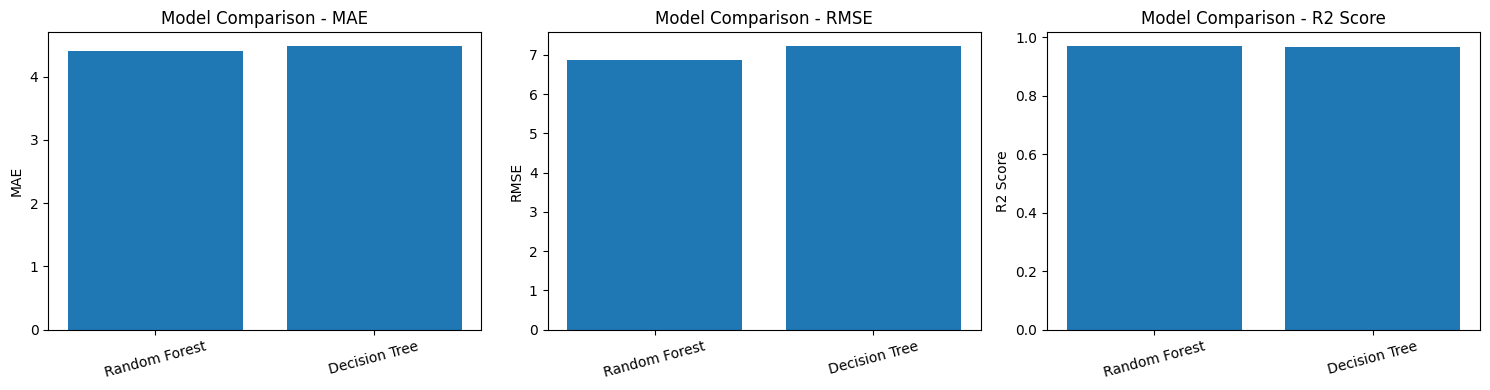

In [88]:
# Fix: Import matplotlib and display model comparison charts

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["MAE", "RMSE", "R2 Score"]

for ax, metric in zip(axes, metrics):
    ax.bar(model_comparison["Model"], model_comparison[metric])
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

=== TOP 15 IMPORTANT FEATURES ===


,feature,importance
301,remainder__total_stops,0.741494
219,categorical__route_id_374,0.115748
220,categorical__route_id_374A,0.080706
231,categorical__route_id_43A,0.009106
58,categorical__route_id_161,0.006699
230,categorical__route_id_43,0.006236
18,categorical__route_id_120,0.003126
188,categorical__route_id_35,0.002259
55,categorical__route_id_159,0.001991
94,categorical__route_id_209,0.001929


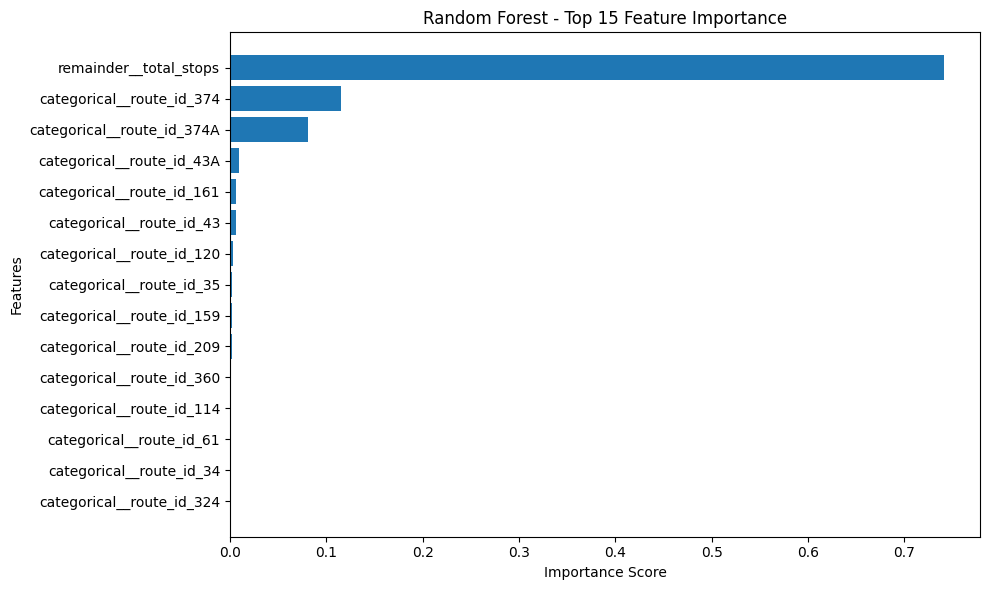

In [89]:
# Step 47: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get trained Random Forest from pipeline
rf = rf_model.named_steps["regressor"]

# Get feature names after One-Hot Encoding
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print("=== TOP 15 IMPORTANT FEATURES ===")
display(importance_df.head(15))

# Plot top 15 features
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [90]:
# Step 48: Validate Actual vs Predicted Trip Durations

validation_df = pd.DataFrame({
    "Actual_Duration": y_test.values,
    "Predicted_Duration": y_pred
})

validation_df["Absolute_Error"] = abs(
    validation_df["Actual_Duration"] -
    validation_df["Predicted_Duration"]
)

print("=== PREDICTION VALIDATION ===")
display(validation_df.head(15).round(2))

print("\nAverage prediction error:",
      round(validation_df["Absolute_Error"].mean(), 2), "minutes")

print("\nPredictions within 5 minutes:",
      round((validation_df["Absolute_Error"] <= 5).mean() * 100, 2), "%")

=== PREDICTION VALIDATION ===


,Actual_Duration,Predicted_Duration,Absolute_Error
0,87.70,88.25,0.55
1,87.70,88.25,0.55
2,87.70,88.25,0.55
3,87.70,88.25,0.55
4,87.70,88.25,0.55
5,87.70,88.25,0.55
6,87.70,88.25,0.55
7,87.70,88.25,0.55
8,40.57,38.50,2.06
9,40.57,38.50,2.06



Average prediction error: 4.4 minutes

Predictions within 5 minutes: 71.38 %


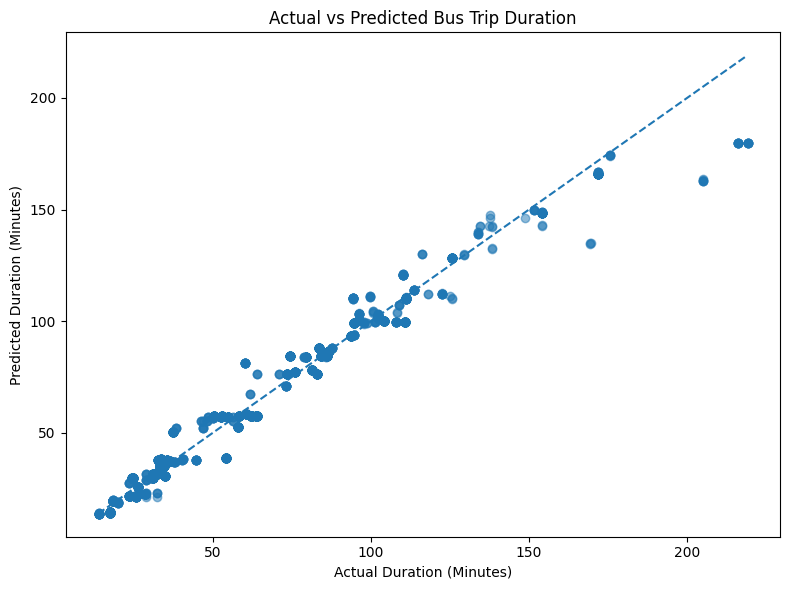

In [91]:
# Step 49: Visualize Actual vs Predicted Duration

plt.figure(figsize=(8, 6))

plt.scatter(
    validation_df["Actual_Duration"],
    validation_df["Predicted_Duration"],
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(
    validation_df["Actual_Duration"].min(),
    validation_df["Predicted_Duration"].min()
)

max_value = max(
    validation_df["Actual_Duration"].max(),
    validation_df["Predicted_Duration"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Bus Trip Duration")
plt.xlabel("Actual Duration (Minutes)")
plt.ylabel("Predicted Duration (Minutes)")
plt.tight_layout()
plt.show()

In [92]:
# STEP 50: Validate model on completely unseen routes

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import numpy as np
import pandas as pd

# Split using route_id as group
route_groups = ml_data["route_id"].astype(str)

route_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

route_train_idx, route_test_idx = next(
    route_splitter.split(X, y, groups=route_groups)
)

X_route_train = X.iloc[route_train_idx]
X_route_test = X.iloc[route_test_idx]

y_route_train = y.iloc[route_train_idx]
y_route_test = y.iloc[route_test_idx]

# Train a fresh copy of the existing Random Forest pipeline
route_model = clone(rf_model)
route_model.fit(X_route_train, y_route_train)

# Predict on routes not seen during training
route_predictions = route_model.predict(X_route_test)

# Evaluate
route_mae = mean_absolute_error(y_route_test, route_predictions)
route_rmse = np.sqrt(
    mean_squared_error(y_route_test, route_predictions)
)
route_r2 = r2_score(y_route_test, route_predictions)

train_routes = set(route_groups.iloc[route_train_idx])
test_routes = set(route_groups.iloc[route_test_idx])

print("=== UNSEEN ROUTE VALIDATION ===")
print("Training trips:", len(X_route_train))
print("Testing trips:", len(X_route_test))
print("Training routes:", len(train_routes))
print("Testing routes:", len(test_routes))
print("Overlapping routes:", len(train_routes & test_routes))

print("\nMAE:", round(route_mae, 2), "minutes")
print("RMSE:", round(route_rmse, 2), "minutes")
print("R2 Score:", round(route_r2, 4))

=== UNSEEN ROUTE VALIDATION ===
Training trips: 8056
Testing trips: 2072
Training routes: 252
Testing routes: 63
Overlapping routes: 0

MAE: 6.66 minutes
RMSE: 9.94 minutes
R2 Score: 0.9257


In [93]:
# STEP 51: Analyze repeated trip duration patterns

print("=== REPEATED TRIP PATTERN ANALYSIS ===")

print("Total trip records:", len(ml_data))

print(
    "Unique route and stop-count combinations:",
    ml_data[["route_id", "total_stops"]].drop_duplicates().shape[0]
)

print(
    "Unique route, stop-count and duration combinations:",
    ml_data[
        ["route_id", "total_stops", "duration_minutes"]
    ].drop_duplicates().shape[0]
)

print("\nTrips per route statistics:")
display(
    ml_data.groupby("route_id")["trip_id"]
    .nunique()
    .describe()
    .to_frame("trips_per_route")
)

print("\nMost frequent route-duration patterns:")
display(
    ml_data.groupby(
        ["route_id", "total_stops", "duration_minutes"]
    ).size()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
    .head(10)
)

=== REPEATED TRIP PATTERN ANALYSIS ===
Total trip records: 10128
Unique route and stop-count combinations: 515
Unique route, stop-count and duration combinations: 627

Trips per route statistics:


,trips_per_route
count,315.000000
mean,32.152381
std,29.740742
min,3.000000
25%,8.000000
50%,22.000000
75%,49.500000
max,175.000000



Most frequent route-duration patterns:


,route_id,total_stops,duration_minutes,trip_count
489,5,14,17.516667,91
490,5,15,18.450000,84
93,149,87,124.233333,64
15,114,43,51.916667,64
277,291,36,51.966667,63
453,372,47,63.500000,59
581,H8,16,16.116667,59
400,350,29,35.100000,59
352,324,45,79.066667,57
131,167,35,50.683333,57


In [95]:
# STEP 52: Generate Final Route Recommendations
# Rebuild required summary from already-loaded GTFS tables

# Unique stops served by each route
route_stops = (
    trips[["route_id", "trip_id"]]
    .merge(
        stop_times[["trip_id", "stop_id"]],
        on="trip_id",
        how="inner"
    )
    [["route_id", "stop_id"]]
    .drop_duplicates()
    .groupby("route_id")["stop_id"]
    .nunique()
    .reset_index(name="unique_stops")
)

# Scheduled trips per route
route_trips = (
    trips.groupby("route_id")["trip_id"]
    .nunique()
    .reset_index(name="total_trips")
)

# Combine route information
recommendations = (
    routes[["route_id", "route_short_name", "route_long_name"]]
    .merge(route_stops, on="route_id", how="left")
    .merge(route_trips, on="route_id", how="left")
)

recommendations[["unique_stops", "total_trips"]] = (
    recommendations[["unique_stops", "total_trips"]].fillna(0)
)

# Categorize routes using quartiles
high_coverage = recommendations["unique_stops"].quantile(0.75)
low_coverage = recommendations["unique_stops"].quantile(0.25)
high_frequency = recommendations["total_trips"].quantile(0.75)
low_frequency = recommendations["total_trips"].quantile(0.25)

recommendations["recommendation"] = np.select(
    [
        (recommendations["unique_stops"] >= high_coverage) &
        (recommendations["total_trips"] >= high_frequency),

        (recommendations["unique_stops"] <= low_coverage) &
        (recommendations["total_trips"] <= low_frequency)
    ],
    [
        "High coverage and frequency - maintain service",
        "Low coverage and frequency - review service needs"
    ],
    default="Moderate coverage/frequency - monitor performance"
)

print("=== FINAL ROUTE RECOMMENDATIONS ===")
display(
    recommendations.sort_values(
        ["unique_stops", "total_trips"],
        ascending=False
    ).head(20)
)

print("\nRecommendation category counts:")
display(
    recommendations["recommendation"]
    .value_counts()
    .to_frame("number_of_routes")
)

=== FINAL ROUTE RECOMMENDATIONS ===


,route_id,route_short_name,route_long_name,unique_stops,total_trips,recommendation
114,231,231,Shilim Gaon ⇆ Marketyard Depot,212,4,Moderate coverage/frequency - monitor performance
259,65A,65A,Patas ⇆ Hadapsar Gadital Solapur Road,193,56,High coverage and frequency - maintain service
63,164,164,Nhavare ⇆ Ma Na Pa Shramik Bhavan,190,12,Moderate coverage/frequency - monitor performance
56,159B,159B,Loni Dhamni ⇆ Ma Na Pa Shramik Bhavan,190,11,Moderate coverage/frequency - monitor performance
142,296,296,Velhe ⇆ Balaji Nagar Corner Satara Road,188,13,Moderate coverage/frequency - monitor performance
102,212,212,Morgaon St Stand ⇆ Hadapsar Gadital,188,3,Moderate coverage/frequency - monitor performance
266,70,70,Mulshi Gaon ⇆ Marketyard Depot,184,9,Moderate coverage/frequency - monitor performance
116,233A,233A,Kolwan Gaon ⇆ Marketyard Depot,183,12,Moderate coverage/frequency - monitor performance
223,368,368,Lonavala Railway Station ⇆ Nigdi Pawale Chowk,177,25,Moderate coverage/frequency - monitor performance
113,228,228,Vadgaon Mawal ⇆ Katraj,173,55,High coverage and frequency - maintain service



Recommendation category counts:


,number_of_routes
recommendation,
Moderate coverage/frequency - monitor performance,293
High coverage and frequency - maintain service,13
Low coverage and frequency - review service needs,9


In [96]:
# STEP 53: RouteRanker - Interactive Prediction Demo

import ipywidgets as widgets
from IPython.display import display, clear_output

route_options = sorted(
    ml_data["route_id"].astype(str).unique()
)

route_dropdown = widgets.Dropdown(
    options=route_options,
    description="Route ID:"
)

start_time_input = widgets.Text(
    value="08:00:00",
    description="Start Time:"
)

stops_input = widgets.IntText(
    value=30,
    description="Total Stops:"
)

predict_button = widgets.Button(
    description="Predict Duration",
    button_style="success"
)

output = widgets.Output()

def predict_trip_duration(button):
    with output:
        clear_output()

        selected_route = route_dropdown.value
        selected_row = ml_data[
            ml_data["route_id"].astype(str) == selected_route
        ].iloc[0]

        try:
            start_minutes = time_to_seconds(
                start_time_input.value
            ) / 60

            demo_input = pd.DataFrame([{
                "start_time_minutes": start_minutes,
                "total_stops": stops_input.value,
                "route_id": selected_route,
                "route_type": str(selected_row["route_type"]),
                "service_id": str(selected_row["service_id"])
            }])

            prediction = rf_model.predict(demo_input)[0]

            print("=== ROUTERANKER PREDICTION ===")
            print("Route ID:", selected_route)
            print("Start time:", start_time_input.value)
            print("Total stops:", stops_input.value)
            print("Predicted scheduled duration:",
                  round(prediction, 2), "minutes")

        except Exception as e:
            print("Error:", e)

predict_button.on_click(predict_trip_duration)

display(
    widgets.VBox([
        route_dropdown,
        start_time_input,
        stops_input,
        predict_button,
        output
    ])
)

In [97]:
# STEP 54: Save RouteRanker Models and Outputs

import os
import joblib

output_dir = "/content/RouteRanker/final_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save trained models
joblib.dump(rf_model, os.path.join(output_dir, "random_forest_model.pkl"))
joblib.dump(dt_model, os.path.join(output_dir, "decision_tree_model.pkl"))

# Save model evaluation results
model_comparison.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

# Save feature importance
importance_df.to_csv(
    os.path.join(output_dir, "feature_importance.csv"),
    index=False
)

# Save prediction validation
validation_df.to_csv(
    os.path.join(output_dir, "prediction_validation.csv"),
    index=False
)

# Save route recommendations
recommendations.to_csv(
    os.path.join(output_dir, "route_recommendations.csv"),
    index=False
)

# Save unseen-route validation metrics
unseen_route_results = pd.DataFrame([{
    "MAE": route_mae,
    "RMSE": route_rmse,
    "R2_Score": route_r2,
    "Training_Routes": len(train_routes),
    "Testing_Routes": len(test_routes),
    "Overlapping_Routes": len(train_routes & test_routes)
}])

unseen_route_results.to_csv(
    os.path.join(output_dir, "unseen_route_validation.csv"),
    index=False
)

print("=== ROUTERANKER OUTPUTS SAVED ===")
for file in sorted(os.listdir(output_dir)):
    print(file)

=== ROUTERANKER OUTPUTS SAVED ===
decision_tree_model.pkl
feature_importance.csv
model_comparison.csv
prediction_validation.csv
random_forest_model.pkl
route_recommendations.csv
unseen_route_validation.csv


In [98]:
# STEP 55: Create RouteRanker Final Project Summary

project_summary = pd.DataFrame([{
    "Project": "RouteRanker - AI-Powered Public Transit Route Optimization",
    "Dataset": "Pune PMPML GTFS",
    "Total_Stops": len(stops),
    "Total_Routes": len(routes),
    "Total_Trips": len(trips),
    "Total_Stop_Time_Records": len(stop_times),
    "ML_Task": "Scheduled Trip Duration Prediction",
    "Best_Model": "Random Forest Regressor",
    "Random_Forest_MAE": 4.40,
    "Random_Forest_RMSE": 6.86,
    "Random_Forest_R2": 0.9692,
    "Decision_Tree_MAE": 4.48,
    "Decision_Tree_RMSE": 7.21,
    "Decision_Tree_R2": 0.9659,
    "Unseen_Route_MAE": 6.66,
    "Unseen_Route_RMSE": 9.94,
    "Unseen_Route_R2": 0.9257,
    "Average_Prediction_Error_Minutes": round(
        validation_df["Absolute_Error"].mean(), 2
    ),
    "Predictions_Within_5_Minutes_Percent": round(
        (validation_df["Absolute_Error"] <= 5).mean() * 100, 2
    )
}])

project_summary.to_csv(
    os.path.join(output_dir, "project_summary.csv"),
    index=False
)

display(project_summary.T)
print("Project summary saved successfully!")

,0
Project,RouteRanker - AI-Powered Public Transit Route ...
Dataset,Pune PMPML GTFS
Total_Stops,6745
Total_Routes,315
Total_Trips,10128
Total_Stop_Time_Records,429302
ML_Task,Scheduled Trip Duration Prediction
Best_Model,Random Forest Regressor
Random_Forest_MAE,4.4
Random_Forest_RMSE,6.86


Project summary saved successfully!


In [99]:
# STEP 56: Generate RouteRanker Final Project Report

!pip install python-docx -q

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
import os

doc = Document()

# Page setup
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Default font
styles = doc.styles
styles["Normal"].font.name = "Times New Roman"
styles["Normal"].font.size = Pt(11)

# Title
title = doc.add_heading("ROUTERANKER", 0)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

subtitle = doc.add_paragraph(
    "AI-Powered Public Transit Route Optimization"
)
subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_paragraph(
    "Final Year Project Report",
    style="Subtitle"
).alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_heading("1. Abstract", level=1)
doc.add_paragraph(
    "RouteRanker is a machine-learning-based public transit analysis "
    "and route optimization project developed using Pune PMPML GTFS data. "
    "The project analyzes routes, stops, trips and scheduled stop times. "
    "It develops regression models to predict scheduled trip duration "
    "using features such as departure time, number of stops, route ID, "
    "route type and service ID. It also generates preliminary route "
    "planning recommendations based on route coverage and scheduled "
    "trip frequency."
)

doc.add_heading("2. Problem Statement", level=1)
doc.add_paragraph(
    "Public transit datasets contain large amounts of route and schedule "
    "information. Analyzing these records manually makes it difficult "
    "to understand route coverage, service frequency and scheduled trip "
    "duration. This project uses data analysis and machine learning to "
    "extract useful insights and estimate scheduled trip duration."
)

doc.add_heading("3. Objectives", level=1)
for item in [
    "Analyze public transit routes, stops and trips.",
    "Study route coverage and scheduled service frequency.",
    "Calculate scheduled trip duration from GTFS stop-time records.",
    "Build and compare regression models.",
    "Validate predictions on unseen routes.",
    "Generate preliminary route planning recommendations.",
    "Develop an interactive trip-duration prediction demo."
]:
    doc.add_paragraph(item, style="List Bullet")

doc.add_heading("4. Dataset Description", level=1)
doc.add_paragraph(
    "The project uses Pune PMPML General Transit Feed Specification "
    "(GTFS) data. The dataset contains:"
)
table = doc.add_table(rows=1, cols=2)
table.style = "Table Grid"
table.rows[0].cells[0].text = "Dataset component"
table.rows[0].cells[1].text = "Records"

for name, count in [
    ("Stops", "6,745"),
    ("Routes", "315"),
    ("Trips", "10,128"),
    ("Stop-time records", "429,302")
]:
    cells = table.add_row().cells
    cells[0].text = name
    cells[1].text = count

doc.add_heading("5. Methodology", level=1)
for heading, description in [
    ("Data preprocessing",
     "GTFS tables were loaded, inspected and combined using their identifiers."),
    ("Trip duration calculation",
     "Scheduled duration was calculated using the first departure time "
     "and last arrival time of each trip."),
    ("Feature engineering",
     "Start time was converted into minutes. Total stops, route ID, "
     "route type and service ID were used as model features."),
    ("Model training",
     "Random Forest Regressor and Decision Tree Regressor were trained "
     "using preprocessing pipelines with one-hot encoding."),
    ("Validation",
     "Models were evaluated using grouped train-test splitting and "
     "a separate unseen-route validation.")
]:
    doc.add_heading(heading, level=2)
    doc.add_paragraph(description)

doc.add_heading("6. Model Performance", level=1)
table = doc.add_table(rows=1, cols=4)
table.style = "Table Grid"

for i, heading in enumerate(["Model", "MAE (min)", "RMSE (min)", "R²"]):
    table.rows[0].cells[i].text = heading

for row in [
    ["Random Forest", "4.40", "6.86", "0.9692"],
    ["Decision Tree", "4.48", "7.21", "0.9659"],
    ["Random Forest (Unseen routes)", "6.66", "9.94", "0.9257"]
]:
    cells = table.add_row().cells
    for i, value in enumerate(row):
        cells[i].text = value

doc.add_paragraph(
    "The Random Forest model achieved the best results on the grouped "
    "trip-level test set. Its mean absolute error was approximately "
    "4.40 minutes. On the separate unseen-route test, its MAE was "
    "approximately 6.66 minutes."
)

doc.add_heading("7. Prediction Demo", level=1)
doc.add_paragraph(
    "An interactive demo was developed using ipywidgets. Users can select "
    "a route, enter a start time and specify the number of stops. The "
    "trained Random Forest model then predicts the scheduled trip duration. "
    "For example, Route 100 with a start time of 08:00:00 and 30 stops "
    "produced a predicted duration of 38.5 minutes."
)

doc.add_heading("8. Limitations", level=1)
doc.add_paragraph(
    "The model predicts scheduled trip duration based on GTFS timetable "
    "data. It does not predict actual traffic-based travel time or "
    "passenger demand because real-time traffic and passenger-count "
    "datasets were not available. Route recommendations are preliminary "
    "and should not be used alone to make service reduction decisions."
)

doc.add_heading("9. Conclusion", level=1)
doc.add_paragraph(
    "RouteRanker demonstrates how public transit schedule data can be "
    "analyzed using data science and machine learning. The project "
    "successfully compares regression models, validates performance "
    "on unseen routes and produces preliminary route planning insights. "
    "Future work can incorporate real-time traffic, GPS and passenger "
    "demand data to support more comprehensive transit optimization."
)

doc.add_heading("10. References", level=1)
doc.add_paragraph(
    "1. Pune PMPML GTFS dataset: "
    "https://github.com/croyla/pmpml-gtfs"
)
doc.add_paragraph(
    "2. GTFS Schedule Reference: https://gtfs.org/documentation/schedule/"
)
doc.add_paragraph(
    "3. Scikit-learn documentation: https://scikit-learn.org/stable/"
)

report_path = os.path.join(output_dir, "RouteRanker_Final_Report.docx")
doc.save(report_path)

print("Report created successfully!")
print("Saved at:", report_path)

Report created successfully!
Saved at: /content/RouteRanker/final_outputs/RouteRanker_Final_Report.docx


In [100]:
# STEP 57: Generate RouteRanker Project Presentation

!pip install python-pptx -q

from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.enum.text import PP_ALIGN
from pptx.dml.color import RGBColor
import os

prs = Presentation()
prs.slide_width = Inches(13.33)
prs.slide_height = Inches(7.5)

def add_slide(title, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[6])

    # Title
    title_box = slide.shapes.add_textbox(
        Inches(0.6), Inches(0.35), Inches(12), Inches(0.8)
    )
    tf = title_box.text_frame
    p = tf.paragraphs[0]
    p.text = title
    p.font.size = Pt(30)
    p.font.bold = True
    p.font.color.rgb = RGBColor(20, 60, 110)

    # Body
    body = slide.shapes.add_textbox(
        Inches(0.9), Inches(1.5), Inches(11.5), Inches(5.3)
    )
    tf = body.text_frame
    tf.word_wrap = True

    for i, bullet in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = bullet
        p.font.size = Pt(21)
        p.space_after = Pt(18)

# Slide 1
add_slide("RouteRanker", [
    "AI-Powered Public Transit Route Optimization",
    "Final Year Project Presentation",
    "Dataset: Pune PMPML GTFS"
])

# Slide 2
add_slide("Problem Statement", [
    "Public transit datasets contain large amounts of route and schedule information.",
    "Manual analysis makes it difficult to understand route coverage and service frequency.",
    "Machine learning can help estimate scheduled trip duration."
])

# Slide 3
add_slide("Project Objectives", [
    "Analyze routes, stops and scheduled trips.",
    "Study route coverage and service frequency.",
    "Predict scheduled trip duration using regression models.",
    "Compare and validate machine learning models.",
    "Generate preliminary route planning recommendations."
])

# Slide 4
add_slide("Dataset Description", [
    "Source: Pune PMPML GTFS dataset.",
    "Stops: 6,745",
    "Routes: 315",
    "Trips: 10,128",
    "Stop-time records: 429,302"
])

# Slide 5
add_slide("Methodology", [
    "GTFS data loading and preprocessing.",
    "Trip duration calculation from scheduled stop times.",
    "Feature engineering and categorical encoding.",
    "Grouped train-test split.",
    "Model training, evaluation and validation."
])

# Slide 6
add_slide("Feature Engineering", [
    "Start time converted into minutes.",
    "Total number of stops in a trip.",
    "Route ID.",
    "Route type.",
    "Service ID.",
    "Target variable: scheduled trip duration in minutes."
])

# Slide 7
add_slide("Machine Learning Models", [
    "Random Forest Regressor.",
    "Decision Tree Regressor.",
    "One-hot encoding for categorical features.",
    "Evaluation metrics: MAE, RMSE and R²."
])

# Slide 8
add_slide("Model Performance", [
    "Random Forest: MAE = 4.40 minutes.",
    "Random Forest: RMSE = 6.86 minutes.",
    "Random Forest: R² = 0.9692.",
    "Decision Tree: MAE = 4.48 minutes.",
    "Decision Tree: RMSE = 7.21 minutes.",
    "Random Forest performed slightly better on the grouped test set."
])

# Slide 9
add_slide("Unseen Route Validation", [
    "Tested the model on routes not present in training.",
    "Training routes: 252.",
    "Testing routes: 63.",
    "MAE: 6.66 minutes.",
    "RMSE: 9.94 minutes.",
    "R²: 0.9257."
])

# Slide 10
add_slide("Route Recommendations", [
    "Analyzed route coverage and scheduled trip frequency.",
    "13 routes categorized as high coverage and high frequency.",
    "9 routes categorized as low coverage and low frequency.",
    "293 routes categorized for monitoring.",
    "Recommendations are preliminary because passenger demand data is unavailable."
])

# Slide 11
add_slide("Interactive Prediction Demo", [
    "Users select a route ID.",
    "Users enter the scheduled start time and total stops.",
    "Random Forest predicts scheduled trip duration.",
    "Example: Route 100, 08:00 start, 30 stops.",
    "Predicted duration: 38.5 minutes."
])

# Slide 12
add_slide("Conclusion and Future Scope", [
    "RouteRanker analyzes public transit schedule data using machine learning.",
    "Random Forest achieved an MAE of approximately 4.40 minutes on the grouped test set.",
    "Future work: integrate GPS, real-time traffic and passenger demand data.",
    "The current model predicts scheduled duration, not actual traffic-based travel time.",
    "Thank You"
])

ppt_path = os.path.join(output_dir, "RouteRanker_Project_Presentation.pptx")
prs.save(ppt_path)

print("PPT created successfully!")
print("Slides:", len(prs.slides))
print("Saved at:", ppt_path)

PPT created successfully!
Slides: 12
Saved at: /content/RouteRanker/final_outputs/RouteRanker_Project_Presentation.pptx
